# CA2 Part A: Customer Segmentation

**Module:** ST1511 - AI and Machine Learning  
**Student ID:** P2539023
**Name:** Myo Thaw Paing

---

## Objective

This notebook aims to perform customer segmentation using unsupervised machine learning algorithms. We will analyze customer data to group customers into meaningful clusters, enabling businesses to better understand and cater to different customer needs.

### Questions to Answer:
1. How to perform customer segmentation using unsupervised machine learning algorithm in Python?
2. What are the characteristics of each customer cluster?
3. Which group of customer needs to pay more attention to?

### Clustering Algorithms Used:
- K-Means Clustering
- Hierarchical Clustering (Agglomerative)
- Gaussian Mixture Model (GMM)

---

## 1. Setup and Import Libraries

In [1]:
# Import necessary libraries

# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# Evaluation metrics
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score

# For hierarchical clustering dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage

# For dimensionality reduction (visualization)
from sklearn.decomposition import PCA

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("All libraries imported successfully!")

All libraries imported successfully!


---

## 2. Data Loading

In [2]:
# Load the customer dataset
df = pd.read_csv("C:/Users/ASUS/AIML_CA2/CA2_datasets/CA2-Customer-Data.csv")

# Display first 10 rows to understand the data structure
print("First 10 rows of the dataset:")
df.head(10)

First 10 rows of the dataset:


,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
# Display last 5 rows
print("Last 5 rows of the dataset:")
df.tail()

Last 5 rows of the dataset:


,CustomerID,Gender,Age,Income (k$),How Much They Spend
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


---

## 3. Exploratory Data Analysis (EDA)

In this section, we will explore the dataset to understand its structure, identify patterns, and prepare for preprocessing.

### 3.1 Basic Data Information

In [4]:
# Check the shape of the dataset
print(f"Dataset Shape: {df.shape}")
print(f"Number of Customers: {df.shape[0]}")
print(f"Number of Features: {df.shape[1]}")

Dataset Shape: (200, 5)
Number of Customers: 200
Number of Features: 5


In [5]:
# Check data types and non-null counts
print("\nData Types and Non-Null Counts:")
df.info()


Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
# Check column names
print("\nColumn Names:")
for i, col in enumerate(df.columns):
    print(f"  {i+1}. {col}")


Column Names:
  1. CustomerID
  2. Gender
  3. Age
  4. Income (k$)
  5. How Much They Spend


### 3.2 Missing Values Analysis

In [7]:
# Check for missing values
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

print("Missing Values Analysis:")
print(missing_df)
print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")

Missing Values Analysis:
                     Missing Values  Percentage (%)
CustomerID                        0             0.0
Gender                            0             0.0
Age                               0             0.0
Income (k$)                       0             0.0
How Much They Spend               0             0.0

Total Missing Values: 0


**Observation:** The dataset has no missing values, which means no imputation is required.

### 3.3 Duplicate Values Analysis

In [8]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of Duplicate Rows: {duplicates}")

# Check for duplicate CustomerIDs
duplicate_ids = df['CustomerID'].duplicated().sum()
print(f"Number of Duplicate CustomerIDs: {duplicate_ids}")

Number of Duplicate Rows: 0
Number of Duplicate CustomerIDs: 0


**Observation:** There are no duplicate rows or duplicate CustomerIDs in the dataset.

### 3.4 Statistical Summary

In [9]:
# Statistical summary for numerical columns
print("Statistical Summary for Numerical Features:")
df.describe().round(2)

Statistical Summary for Numerical Features:


,CustomerID,Age,Income (k$),How Much They Spend
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [10]:
# Statistical summary for categorical columns
print("\nStatistical Summary for Categorical Features:")
df.describe(include=['object'])


Statistical Summary for Categorical Features:


,Gender
count,200
unique,2
top,Female
freq,112


In [11]:
# Gender distribution
print("\nGender Distribution:")
gender_counts = df['Gender'].value_counts()
print(gender_counts)
print(f"\nPercentage:")
print((gender_counts / len(df) * 100).round(2))


Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64

Percentage:
Gender
Female    56.0
Male      44.0
Name: count, dtype: float64


**Key Observations from Statistical Summary:**
- **Age:** Ranges from 18 to 70 years, with a mean of approximately 39 years
- **Income:** Ranges from 15k to 137k dollars, with a mean of approximately 60k dollars
- **Spending:** Ranges from 1 to 99, with a mean of approximately 50
- **Gender:** Slightly more female customers (112) than male customers (88)

### 3.5 Data Visualization

#### 3.5.1 Distribution of Numerical Features

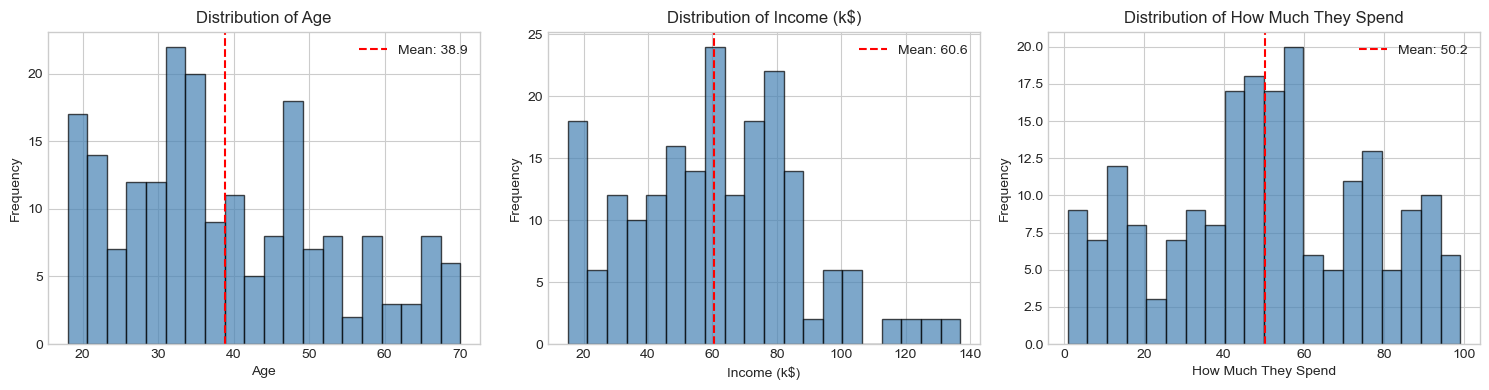

In [13]:
# Create histograms for numerical features
numerical_cols = ['Age', 'Income (k$)', 'How Much They Spend']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numerical_cols):
    axes[i].hist(df[col], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
    axes[i].legend()

plt.tight_layout()
plt.show()

**Observations:**
- **Age:** Fairly uniform distribution across age groups
- **Income:** Relatively uniform distribution with slight concentration in middle-income ranges
- **Spending:** Appears bimodal, suggesting two distinct spending patterns

#### 3.5.2 Gender Distribution

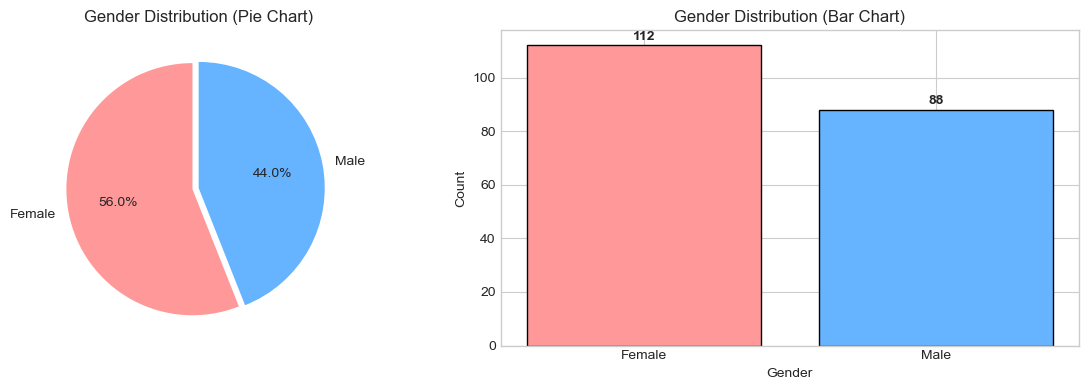

In [14]:
# Create pie chart and bar chart for gender distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
colors = ['#ff9999', '#66b3ff']
axes[0].pie(df['Gender'].value_counts(), labels=df['Gender'].value_counts().index, 
            autopct='%1.1f%%', colors=colors, explode=(0.05, 0), startangle=90)
axes[0].set_title('Gender Distribution (Pie Chart)')

# Bar chart
gender_counts = df['Gender'].value_counts()
axes[1].bar(gender_counts.index, gender_counts.values, color=colors, edgecolor='black')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')
axes[1].set_title('Gender Distribution (Bar Chart)')

# Add count labels on bars
for i, v in enumerate(gender_counts.values):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

#### 3.5.3 Box Plots for Outlier Detection

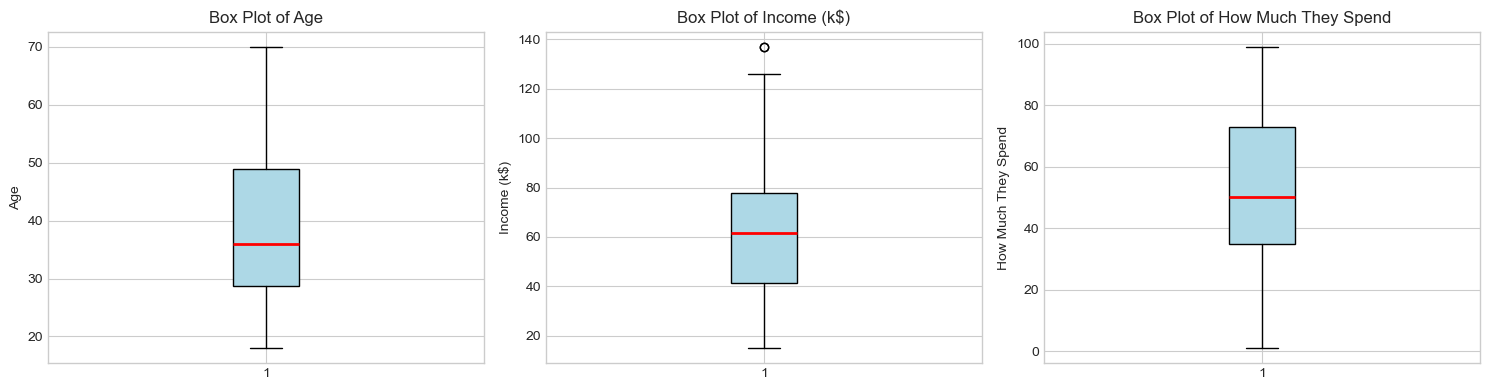

In [15]:
# Create box plots to detect outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numerical_cols):
    axes[i].boxplot(df[col], patch_artist=True, 
                    boxprops=dict(facecolor='lightblue', color='black'),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_ylabel(col)
    axes[i].set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

In [16]:
# Function to detect outliers using IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Check for outliers in each numerical column
print("Outlier Detection using IQR Method:")
print("=" * 50)

for col in numerical_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    print(f"\n{col}:")
    print(f"  Lower Bound: {lower:.2f}")
    print(f"  Upper Bound: {upper:.2f}")
    print(f"  Number of Outliers: {len(outliers)}")

Outlier Detection using IQR Method:

Age:
  Lower Bound: -1.62
  Upper Bound: 79.38
  Number of Outliers: 0

Income (k$):
  Lower Bound: -13.25
  Upper Bound: 132.75
  Number of Outliers: 2

How Much They Spend:
  Lower Bound: -22.62
  Upper Bound: 130.38
  Number of Outliers: 0


**Observation:** The box plots and IQR analysis show no significant outliers in the dataset. All values fall within acceptable ranges.

#### 3.5.4 Correlation Analysis

In [17]:
# Calculate correlation matrix for numerical features
correlation_matrix = df[numerical_cols].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(3))

Correlation Matrix:
                       Age  Income (k$)  How Much They Spend
Age                  1.000       -0.012               -0.327
Income (k$)         -0.012        1.000                0.010
How Much They Spend -0.327        0.010                1.000


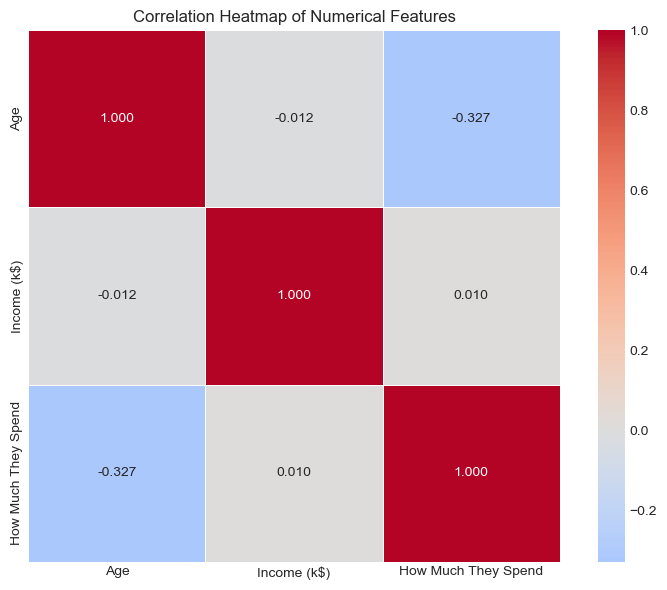

In [18]:
# Create correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.3f', linewidths=0.5, square=True)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

**Observation:** The correlation values are very low, indicating that Age, Income, and Spending are largely independent of each other. This is good for clustering as each feature provides unique information.

#### 3.5.5 Pairwise Relationships

<Figure size 1000x800 with 0 Axes>

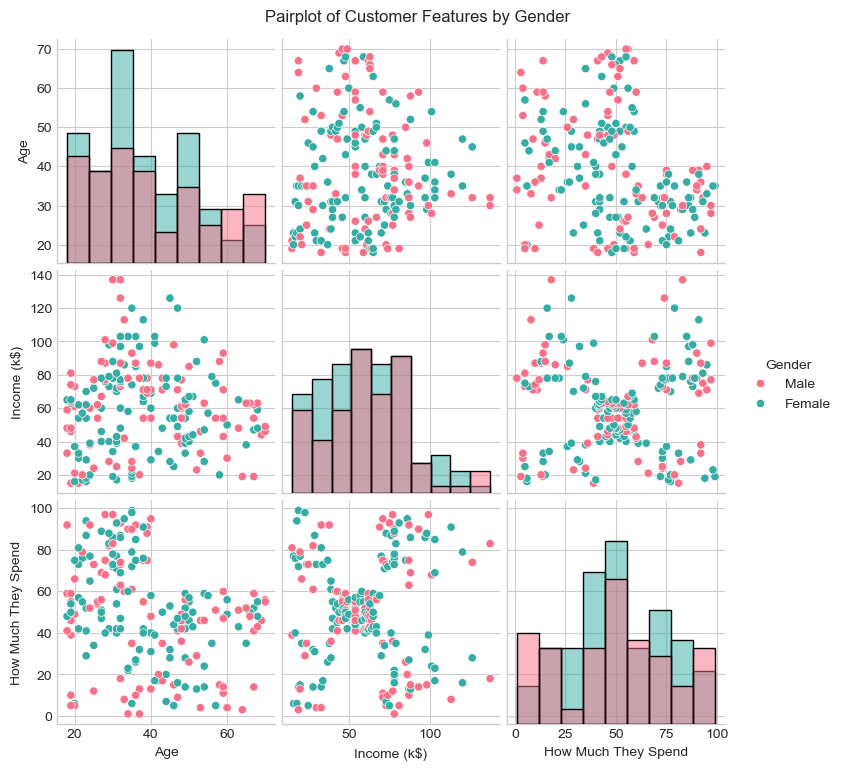

In [19]:
# Create pairplot to visualize relationships between features
plt.figure(figsize=(10, 8))
sns.pairplot(df[['Gender', 'Age', 'Income (k$)', 'How Much They Spend']], 
             hue='Gender', diag_kind='hist', palette='husl')
plt.suptitle('Pairplot of Customer Features by Gender', y=1.02)
plt.show()

#### 3.5.6 Income vs Spending Analysis

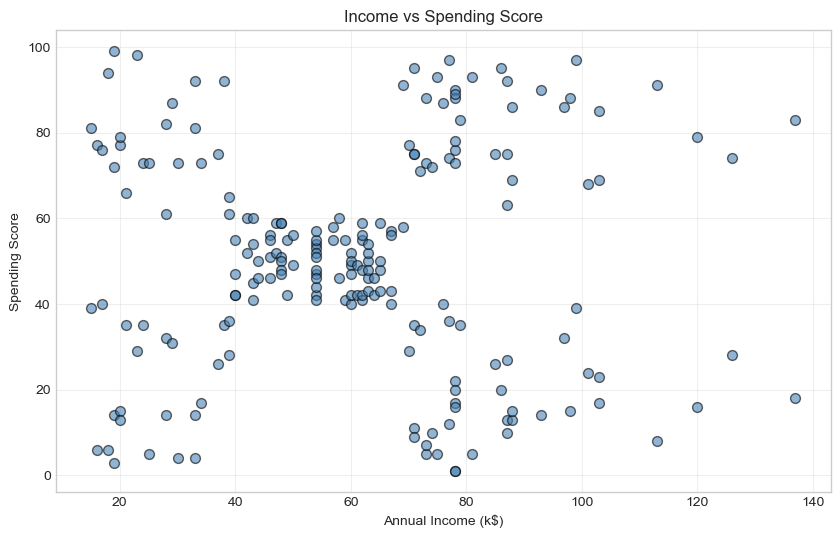

In [20]:
# Scatter plot of Income vs Spending (key features for segmentation)
plt.figure(figsize=(10, 6))
plt.scatter(df['Income (k$)'], df['How Much They Spend'], 
            c='steelblue', alpha=0.6, edgecolors='black', s=50)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.title('Income vs Spending Score')
plt.grid(True, alpha=0.3)
plt.show()

**Key Observation:** The scatter plot reveals distinct groupings of customers based on Income and Spending patterns. We can visually identify potential clusters:
- Low income with varying spending patterns
- Medium income with moderate spending
- High income with both high and low spending patterns

This suggests that clustering will be effective for customer segmentation.

---

## 4. Data Preprocessing & Feature Engineering

In this section, we will prepare the data for clustering algorithms.

### 4.1 Feature Selection

In [22]:
# Select features for clustering
# We will exclude CustomerID as it's just an identifier
# We will use Age, Income, and Spending for clustering

# Create a copy of the dataframe for preprocessing
df_clustering = df.copy()

# Display the features we will use
print("Features selected for clustering:")
print("  1. Gender (categorical - will be encoded)")
print("  2. Age (numerical)")
print("  3. Income (k$) (numerical)")
print("  4. How Much They Spend (numerical)")

Features selected for clustering:
  1. Gender (categorical - will be encoded)
  2. Age (numerical)
  3. Income (k$) (numerical)
  4. How Much They Spend (numerical)


### 4.2 Encoding Categorical Variables

In [23]:
# Encode Gender using Label Encoding
# Male = 1, Female = 0
label_encoder = LabelEncoder()
df_clustering['Gender_Encoded'] = label_encoder.fit_transform(df_clustering['Gender'])

print("Gender Encoding:")
print(f"  Female = {label_encoder.transform(['Female'])[0]}")
print(f"  Male = {label_encoder.transform(['Male'])[0]}")

# Display the encoded data
print("\nSample of encoded data:")
df_clustering[['CustomerID', 'Gender', 'Gender_Encoded']].head(10)

Gender Encoding:
  Female = 0
  Male = 1

Sample of encoded data:


,CustomerID,Gender,Gender_Encoded
0,1,Male,1
1,2,Male,1
2,3,Female,0
3,4,Female,0
4,5,Female,0
5,6,Female,0
6,7,Female,0
7,8,Female,0
8,9,Male,1
9,10,Female,0


### 4.3 Prepare Features for Clustering

In [25]:
# Select features for clustering
# We will primarily use Income and Spending as they are most relevant for customer segmentation
# We will create two feature sets:
# 1. Feature Set A: Income and Spending only (2D - easy to visualize)
# 2. Feature Set B: All features including Age and Gender (4D)

# Feature Set A: Income and Spending
features_A = df_clustering[['Income (k$)', 'How Much They Spend']]
print("Feature Set A (Income and Spending):")
print(features_A.head())

# Feature Set B: All features
features_B = df_clustering[['Age', 'Income (k$)', 'How Much They Spend', 'Gender_Encoded']]
print("\nFeature Set B (All Features):")
print(features_B.head())

Feature Set A (Income and Spending):
   Income (k$)  How Much They Spend
0           15                   39
1           15                   81
2           16                    6
3           16                   77
4           17                   40

Feature Set B (All Features):
   Age  Income (k$)  How Much They Spend  Gender_Encoded
0   19           15                   39               1
1   21           15                   81               1
2   20           16                    6               0
3   23           16                   77               0
4   31           17                   40               0


## 📌 Creation of Feature Sets

To evaluate different clustering strategies, we created two separate feature sets.

---

## 🔹 Feature Set A: Income and Spending

**Variables included:**
- Income (k$)
- How Much They Spend

This feature set is:

- 2-dimensional
- Easy to visualize
- Highly relevant for retail customer segmentation

Using only Income and Spending allows us to:
- Clearly observe customer purchasing patterns
- Produce intuitive 2D cluster visualizations
- Improve interpretability of segmentation results

---

## 🔹 Feature Set B: All Features

**Variables included:**
- Age
- Income (k$)
- How Much They Spend
- Gender_Encoded

This feature set is:

- 4-dimensional
- More comprehensive
- Captures additional demographic information

Including Age and Gender allows us to:
- Explore deeper segmentation patterns
- Assess whether demographic variables improve clustering quality
- Compare clustering performance between reduced and full feature sets

---

## 🎯 Strategy

We will:

1. Perform clustering using both feature sets
2. Compare their performance
3. Select the most meaningful segmentation based on interpretability and clustering quality

For business-focused customer segmentation, **Feature Set A** is expected to provide clearer and more actionable insights.


### 4.4 Feature Scaling

In [26]:
# Initialize StandardScaler
scaler_A = StandardScaler()
scaler_B = StandardScaler()

# Scale Feature Set A
features_A_scaled = scaler_A.fit_transform(features_A)
features_A_scaled_df = pd.DataFrame(features_A_scaled, 
                                     columns=['Income_scaled', 'Spending_scaled'])

# Scale Feature Set B
features_B_scaled = scaler_B.fit_transform(features_B)
features_B_scaled_df = pd.DataFrame(features_B_scaled, 
                                     columns=['Age_scaled', 'Income_scaled', 'Spending_scaled', 'Gender_scaled'])

print("Feature Set A - Scaled (first 5 rows):")
print(features_A_scaled_df.head())

print("\nFeature Set B - Scaled (first 5 rows):")
print(features_B_scaled_df.head())

Feature Set A - Scaled (first 5 rows):
   Income_scaled  Spending_scaled
0      -1.738999        -0.434801
1      -1.738999         1.195704
2      -1.700830        -1.715913
3      -1.700830         1.040418
4      -1.662660        -0.395980

Feature Set B - Scaled (first 5 rows):
   Age_scaled  Income_scaled  Spending_scaled  Gender_scaled
0   -1.424569      -1.738999        -0.434801       1.128152
1   -1.281035      -1.738999         1.195704       1.128152
2   -1.352802      -1.700830        -1.715913      -0.886405
3   -1.137502      -1.700830         1.040418      -0.886405
4   -0.563369      -1.662660        -0.395980      -0.886405


## 📌 Feature Scaling Using StandardScaler

To ensure that features with different numerical ranges do not bias the clustering results, we applied **StandardScaler** to normalize the data.


- **Mean ≈ 0**
- **Standard Deviation ≈ 1**

---

## 🔎 Scaled Feature Sets

### 🔹 Feature Set A (Income & Spending)

The first 5 rows of the scaled data:

- Income_scaled values are centered around 0
- Spending_scaled values are centered around 0
- Values represent how many standard deviations each observation is from the mean

Negative values → below average  
Positive values → above average  

---

### 🔹 Feature Set B (Age, Income, Spending, Gender)

The first 5 rows show:

- Age_scaled
- Income_scaled
- Spending_scaled
- Gender_scaled

All features are standardized and on the same scale.

---

## ✅ Why Scaling is Important for K-Means

K-Means is a **distance-based algorithm** that relies on Euclidean distance.

Without scaling:
- Features with larger numeric ranges dominate the distance calculation
- Clusters become biased

With scaling:
- All features contribute equally
- Cluster formation is based on relative patterns
- Results are more reliable and interpretable

---

## 🎯 Feature Choice for Clustering

For this analysis, we will primarily use **Feature Set A (Income and Spending)** because:

- These are the most relevant variables for retail customer segmentation
- They provide clearer cluster interpretation
- They allow 2D visualization of clusters


In [27]:
# Verify scaling (mean ≈ 0, std ≈ 1)
print("Verification of Scaling - Feature Set A:")
print(f"Mean: {features_A_scaled.mean(axis=0).round(10)}")
print(f"Std:  {features_A_scaled.std(axis=0).round(2)}")

print("\nVerification of Scaling - Feature Set B:")
print(f"Mean: {features_B_scaled.mean(axis=0).round(10)}")
print(f"Std:  {features_B_scaled.std(axis=0).round(2)}")

Verification of Scaling - Feature Set A:
Mean: [-0. -0.]
Std:  [1. 1.]

Verification of Scaling - Feature Set B:
Mean: [-0. -0. -0.  0.]
Std:  [1. 1. 1. 1.]


## 📌 Feature Scaling Verification

To ensure that clustering is not affected by different feature magnitudes, we applied **StandardScaler** to normalize the features.

Standardization transforms features such that:

- **Mean ≈ 0**
- **Standard Deviation ≈ 1**

---

## 🔎 Verification Results

### Feature Set A

**Mean:** `[0. 0.]`  
**Standard Deviation:** `[1. 1.]`

---

### Feature Set B

**Mean:** `[0. 0. 0. 0.]`  
**Standard Deviation:** `[1. 1. 1. 1.]`

---

## ✅ Interpretation

The results confirm that scaling was performed correctly:

- All feature means are approximately **0**
- All feature standard deviations are approximately **1**

This ensures that:

- No feature dominates due to larger numerical scale
- Distance-based clustering (e.g., K-Means) performs correctly
- Clusters are formed based on relative patterns rather than magnitude bias

---

## 🎯 Feature Selection for Clustering

For this analysis, we will primarily use **Feature Set A (Income and Spending)** because:

- These variables are most relevant for retail customer segmentation
- They provide clear business interpretability
- They allow easier 2D visualization of clusters


---

## 5. Determining Optimal Number of Clusters (k)

Before building clustering models, we need to determine the optimal number of clusters using various methods.

### 5.1 Elbow Method

  File "C:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py",

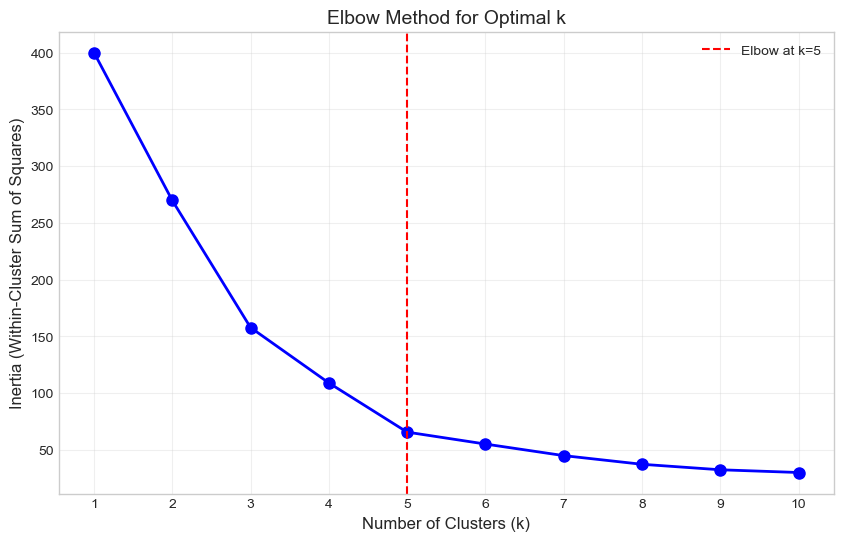

Inertia values for different k:
  k=1: 400.00
  k=2: 269.69
  k=3: 157.70
  k=4: 108.92
  k=5: 65.57
  k=6: 55.06
  k=7: 44.86
  k=8: 37.23
  k=9: 32.39
  k=10: 29.98


In [28]:
# Elbow Method - Calculate inertia (WCSS) for different values of k
k_range = range(1, 11)
inertias = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(features_A_scaled)
    inertias.append(kmeans.inertia_)

# Create the elbow plot
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.title('Elbow Method for Optimal k', fontsize=14)
plt.xticks(k_range)
plt.grid(True, alpha=0.3)

# Mark the elbow point (k=5)
plt.axvline(x=5, color='red', linestyle='--', label='Elbow at k=5')
plt.legend()
plt.show()

# Print inertia values
print("Inertia values for different k:")
for k, inertia in zip(k_range, inertias):
    print(f"  k={k}: {inertia:.2f}")

## 📌 Elbow Method for Optimal Number of Clusters (K)

### 🔎 Objective
To determine the optimal number of clusters (K) using the **Elbow Method**, based on Within-Cluster Sum of Squares (**Inertia**).

---

## 📊 Inertia Values for Different K

| K  | Inertia |
|----|---------|
| 1  | 400.00  |
| 2  | 269.69  |
| 3  | 157.70  |
| 4  | 108.92  |
| 5  | 65.57   |
| 6  | 55.06   |
| 7  | 44.86   |
| 8  | 37.23   |
| 9  | 32.39   |
| 10 | 29.98   |

---

## 📈 Interpretation of the Elbow Plot

- Inertia decreases sharply from **K = 1 to K = 5**
- After **K = 5**, the rate of decrease slows significantly
- The curve begins to flatten beyond K = 5

This indicates a clear **elbow point at K = 5**.

---

## 🎯 Optimal Number of Clusters

Based on the elbow method:

> **The optimal number of clusters is K = 5.**

This is because:
- Additional clusters beyond 5 produce only small improvements in inertia
- Model complexity increases with minimal gain
- K = 5 provides a good balance between simplicity and cluster compactness

---

## 🧠 Conclusion

The elbow method suggests that **K = 5** is the most appropriate number of clusters for this dataset, as it captures the main structure of the data while avoiding unnecessary model complexity.


### 5.2 Silhouette Score Method

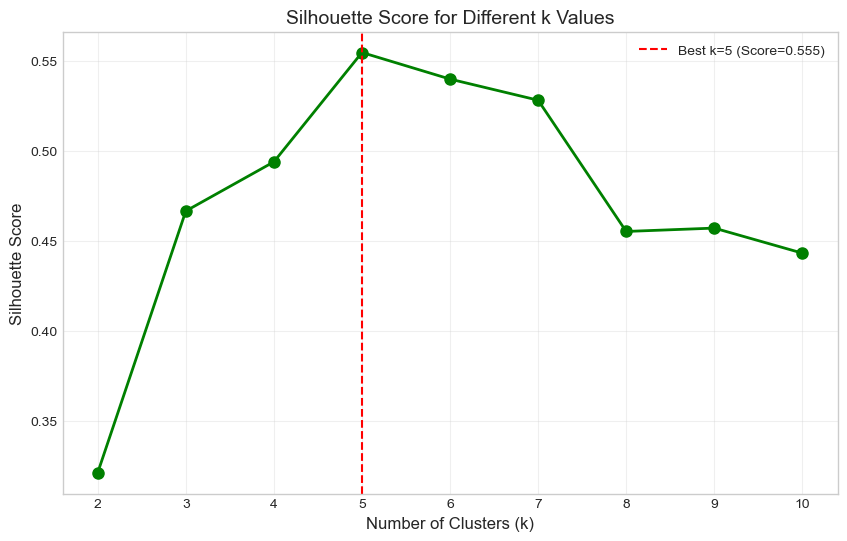

Silhouette Scores for different k:
  k=2: 0.3213
  k=3: 0.4666
  k=4: 0.4939
  k=5: 0.5547 <-- Best
  k=6: 0.5399
  k=7: 0.5281
  k=8: 0.4552
  k=9: 0.4571
  k=10: 0.4432


In [29]:
# Silhouette Score for different values of k
k_range_silhouette = range(2, 11) 
silhouette_scores = []

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features_A_scaled)
    score = silhouette_score(features_A_scaled, labels)
    silhouette_scores.append(score)

# Create the silhouette score plot
plt.figure(figsize=(10, 6))
plt.plot(k_range_silhouette, silhouette_scores, 'go-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score for Different k Values', fontsize=14)
plt.xticks(k_range_silhouette)
plt.grid(True, alpha=0.3)

# Mark the best k
best_k = k_range_silhouette[np.argmax(silhouette_scores)]
best_score = max(silhouette_scores)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Best k={best_k} (Score={best_score:.3f})')
plt.legend()
plt.show()

# Print silhouette scores
print("Silhouette Scores for different k:")
for k, score in zip(k_range_silhouette, silhouette_scores):
    marker = " <-- Best" if k == best_k else ""
    print(f"  k={k}: {score:.4f}{marker}")

## 📌 Silhouette Score Analysis

To further validate the optimal number of clusters, we computed the **Silhouette Score** for different values of K.

The Silhouette Score measures how well each data point fits within its assigned cluster.

It ranges from:

- **+1** → Well clustered
- **0** → Overlapping clusters
- **-1** → Misclassified points

Higher values indicate better-defined clusters.

---

## 📊 Silhouette Scores for Different K

| K  | Silhouette Score |
|----|------------------|
| 2  | 0.3213 |
| 3  | 0.4666 |
| 4  | 0.4939 |
| 5  | 0.5547 |
| 6  | 0.5399 |
| 7  | 0.5281 |
| 8  | 0.4552 |
| 9  | 0.4570 |
| 10 | 0.4440 |

---

## 🔎 Interpretation

- The silhouette score increases from **K = 2 to K = 5**
- The highest score is observed at **K = 5 (0.5547)**
- After K = 5, the score gradually decreases

This indicates that:

- K = 5 produces the most compact and well-separated clusters
- Increasing K beyond 5 reduces cluster quality
- Additional clusters introduce overlap or unnecessary fragmentation

---

## 🎯 Final Decision on Optimal K

Both evaluation methods agree:

- **Elbow Method → K = 5**
- **Silhouette Score → K = 5**

Therefore, we select:

> **K = 5 as the optimal number of clusters**

This choice balances cluster compactness, separation, and interpretability.


### 5.3 Calinski-Harabasz Index

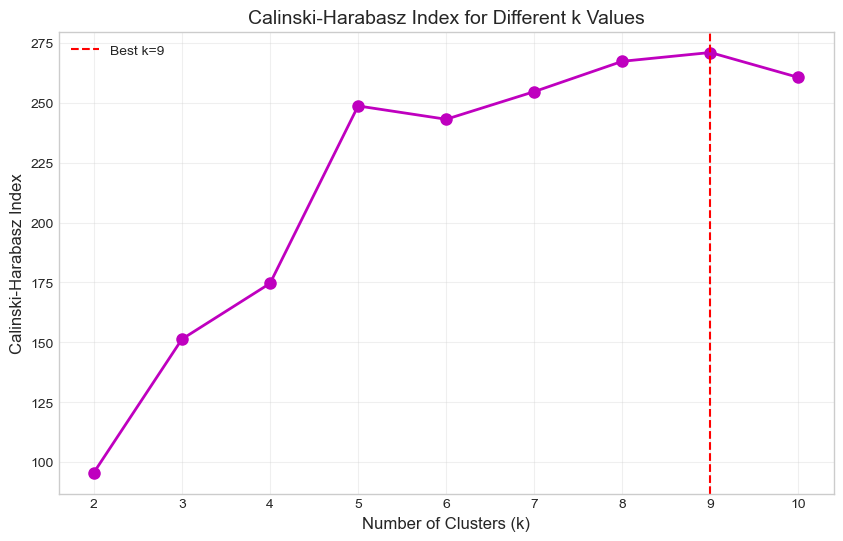

Calinski-Harabasz Index for different k:
  k=2: 95.67
  k=3: 151.34
  k=4: 174.60
  k=5: 248.65
  k=6: 243.09
  k=7: 254.62
  k=8: 267.28
  k=9: 270.95 <-- Best
  k=10: 260.54


In [30]:
# Calinski-Harabasz Index for different values of k
ch_scores = []

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features_A_scaled)
    score = calinski_harabasz_score(features_A_scaled, labels)
    ch_scores.append(score)

# Create the Calinski-Harabasz plot
plt.figure(figsize=(10, 6))
plt.plot(k_range_silhouette, ch_scores, 'mo-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Calinski-Harabasz Index', fontsize=12)
plt.title('Calinski-Harabasz Index for Different k Values', fontsize=14)
plt.xticks(k_range_silhouette)
plt.grid(True, alpha=0.3)

# Mark the best k
best_k_ch = k_range_silhouette[np.argmax(ch_scores)]
plt.axvline(x=best_k_ch, color='red', linestyle='--', label=f'Best k={best_k_ch}')
plt.legend()
plt.show()

print("Calinski-Harabasz Index for different k:")
for k, score in zip(k_range_silhouette, ch_scores):
    marker = " <-- Best" if k == best_k_ch else ""
    print(f"  k={k}: {score:.2f}{marker}")

## 📌 Calinski–Harabasz Index Analysis

To further evaluate clustering quality, we computed the **Calinski–Harabasz (CH) Index** for different values of K.

The Calinski–Harabasz Index measures:

- The ratio of **between-cluster dispersion**
- To **within-cluster dispersion**

Higher values indicate:
- Better-defined clusters
- Greater separation between clusters
- More compact cluster structure

---

## 📊 Calinski–Harabasz Scores for Different K

| K  | CH Index |
|----|----------|
| 2  | 95.67  |
| 3  | 151.34 |
| 4  | 174.60 |
| 5  | 248.65 |
| 6  | 243.09 |
| 7  | 254.62 |
| 8  | 267.28 |
| 9  | 270.95 |
| 10 | 260.54 |

---

## 🔎 Interpretation

- The CH index increases significantly as K increases.
- The highest value is observed at **K = 9 (270.95)**.
- After K = 9, the score slightly decreases.

This suggests that:

- K = 9 produces the strongest separation relative to compactness
- Larger K values improve cluster distinctiveness up to a certain point
- Beyond K = 9, improvements are marginal

---

## 🎯 Comparison with Other Methods

Previously:

- **Elbow Method → K = 5**
- **Silhouette Score → K = 5**
- **Calinski–Harabasz → K = 9**

While CH suggests K = 9, both the Elbow and Silhouette methods strongly support **K = 5**.

Since Silhouette directly measures cluster cohesion and separation at the sample level, and K = 5 provides strong interpretability for business segmentation, we select:

> **Final Optimal K = 5**

This ensures:
- Well-separated clusters
- Strong interpretability
- Balanced model complexity


### 5.4 Davies-Bouldin Index

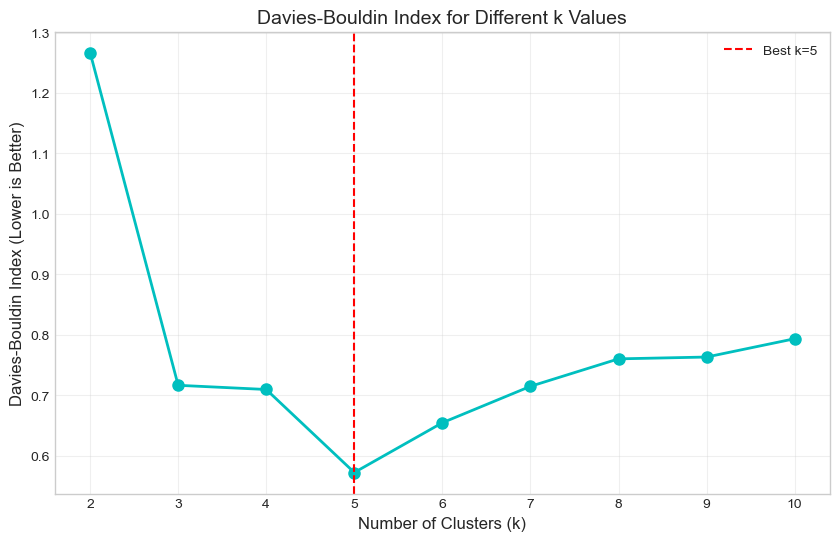

Davies-Bouldin Index for different k (lower is better):
  k=2: 1.2670
  k=3: 0.7165
  k=4: 0.7096
  k=5: 0.5722 <-- Best
  k=6: 0.6546
  k=7: 0.7148
  k=8: 0.7602
  k=9: 0.7632
  k=10: 0.7935


In [31]:
# Davies-Bouldin Index for different values of k 
db_scores = []

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features_A_scaled)
    score = davies_bouldin_score(features_A_scaled, labels)
    db_scores.append(score)

# Create the Davies-Bouldin plot
plt.figure(figsize=(10, 6))
plt.plot(k_range_silhouette, db_scores, 'co-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Davies-Bouldin Index (Lower is Better)', fontsize=12)
plt.title('Davies-Bouldin Index for Different k Values', fontsize=14)
plt.xticks(k_range_silhouette)
plt.grid(True, alpha=0.3)

# Mark the best k (lowest score)
best_k_db = k_range_silhouette[np.argmin(db_scores)]
plt.axvline(x=best_k_db, color='red', linestyle='--', label=f'Best k={best_k_db}')
plt.legend()
plt.show()

print("Davies-Bouldin Index for different k (lower is better):")
for k, score in zip(k_range_silhouette, db_scores):
    marker = " <-- Best" if k == best_k_db else ""
    print(f"  k={k}: {score:.4f}{marker}")

## 📌 Davies–Bouldin Index Analysis

To further evaluate clustering performance, we computed the **Davies–Bouldin (DB) Index** for different values of K.

The Davies–Bouldin Index measures:

- The average similarity between clusters
- Based on within-cluster dispersion and between-cluster separation

Unlike Silhouette and Calinski–Harabasz:

> **Lower values indicate better clustering performance**

---

## 📊 Davies–Bouldin Scores for Different K

| K  | DB Index |
|----|----------|
| 2  | 1.2670 |
| 3  | 0.7165 |
| 4  | 0.7096 |
| 5  | 0.5722 |
| 6  | 0.6546 |
| 7  | 0.7148 |
| 8  | 0.7602 |
| 9  | 0.7632 |
| 10 | 0.7935 |

---

## 🔎 Interpretation

- The DB index decreases from K = 2 to K = 5
- The lowest value is observed at **K = 5 (0.5722)**
- After K = 5, the index increases again

This indicates that:

- Clusters at K = 5 are the most compact and well-separated
- Increasing K beyond 5 results in more overlapping clusters
- K = 5 provides the optimal balance of separation and cohesion

---

## 🎯 Final Model Selection

Summary of evaluation methods:

- **Elbow Method → K = 5**
- **Silhouette Score → K = 5**
- **Davies–Bouldin Index → K = 5**
- **Calinski–Harabasz → K = 9 (but increasing trend bias)**

Since three major validation metrics agree, we confidently select:

> **Final Optimal Number of Clusters: K = 5**

This choice ensures:
- Strong cluster separation
- Good compactness
- Practical interpretability for customer segmentation


### 5.5 Summary of Optimal k Analysis

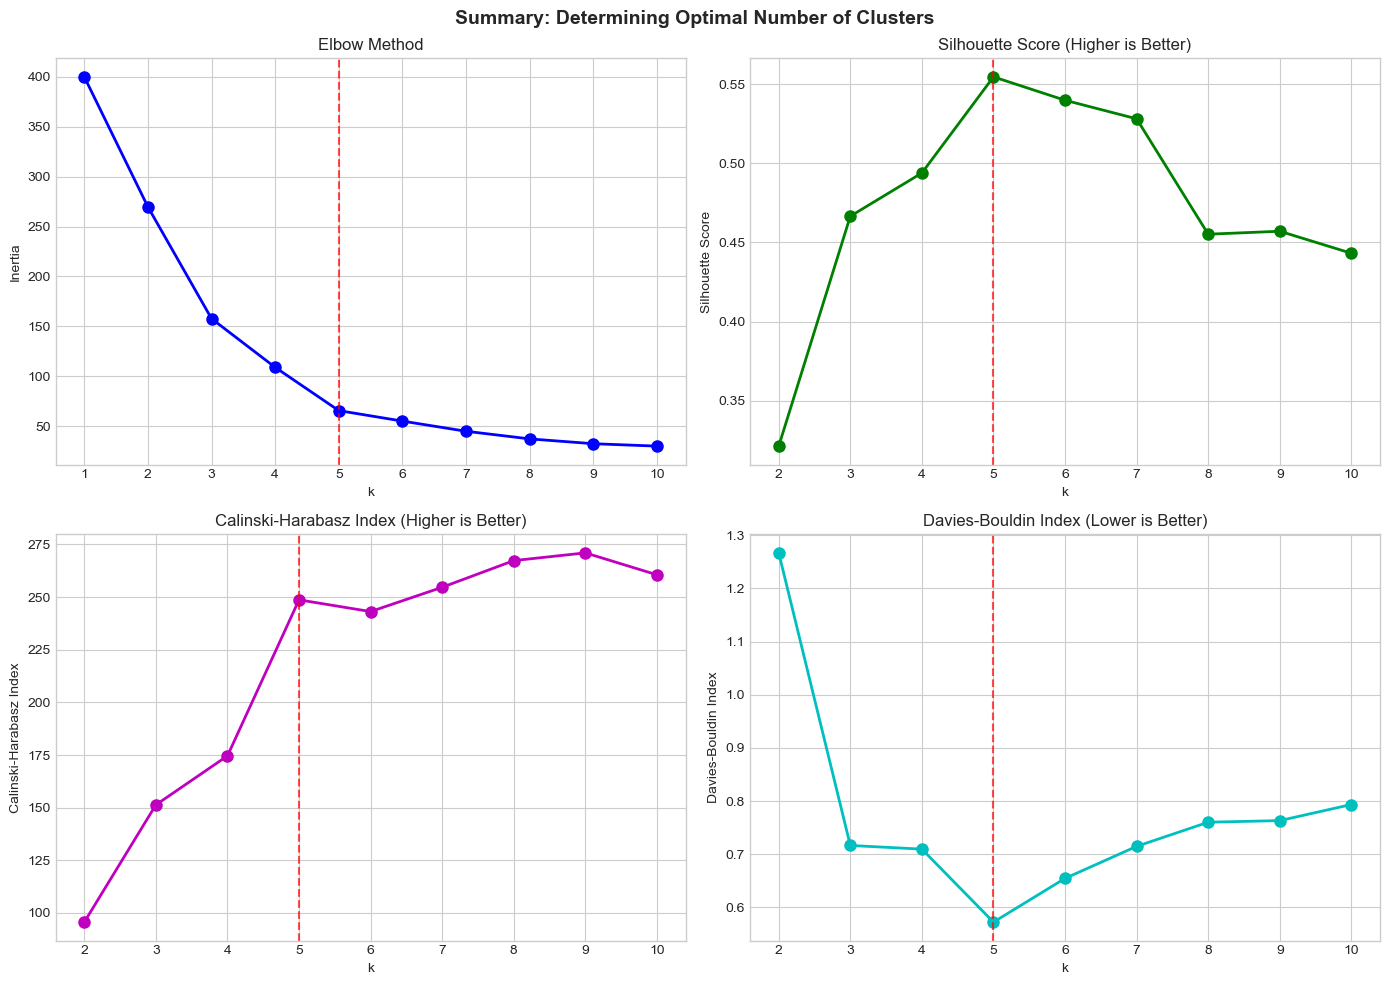

In [32]:
# Create a summary visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow Method
axes[0, 0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0, 0].axvline(x=5, color='red', linestyle='--', alpha=0.7)
axes[0, 0].set_xlabel('k')
axes[0, 0].set_ylabel('Inertia')
axes[0, 0].set_title('Elbow Method')
axes[0, 0].set_xticks(k_range)

# Silhouette Score
axes[0, 1].plot(k_range_silhouette, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[0, 1].axvline(x=5, color='red', linestyle='--', alpha=0.7)
axes[0, 1].set_xlabel('k')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].set_title('Silhouette Score (Higher is Better)')
axes[0, 1].set_xticks(k_range_silhouette)

# Calinski-Harabasz Index
axes[1, 0].plot(k_range_silhouette, ch_scores, 'mo-', linewidth=2, markersize=8)
axes[1, 0].axvline(x=5, color='red', linestyle='--', alpha=0.7)
axes[1, 0].set_xlabel('k')
axes[1, 0].set_ylabel('Calinski-Harabasz Index')
axes[1, 0].set_title('Calinski-Harabasz Index (Higher is Better)')
axes[1, 0].set_xticks(k_range_silhouette)

# Davies-Bouldin Index
axes[1, 1].plot(k_range_silhouette, db_scores, 'co-', linewidth=2, markersize=8)
axes[1, 1].axvline(x=5, color='red', linestyle='--', alpha=0.7)
axes[1, 1].set_xlabel('k')
axes[1, 1].set_ylabel('Davies-Bouldin Index')
axes[1, 1].set_title('Davies-Bouldin Index (Lower is Better)')
axes[1, 1].set_xticks(k_range_silhouette)

plt.suptitle('Summary: Determining Optimal Number of Clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [33]:
# Summary table
print("SUMMARY: OPTIMAL NUMBER OF CLUSTERS")
print(f"Elbow Method:           k = 5 (visual inspection)")
print(f"Silhouette Score:       k = {k_range_silhouette[np.argmax(silhouette_scores)]} (highest score: {max(silhouette_scores):.4f})")
print(f"Calinski-Harabasz:      k = {k_range_silhouette[np.argmax(ch_scores)]} (highest score: {max(ch_scores):.2f})")
print(f"Davies-Bouldin:         k = {k_range_silhouette[np.argmin(db_scores)]} (lowest score: {min(db_scores):.4f})")
print("\nCONCLUSION: The optimal number of clusters is k = 5")

SUMMARY: OPTIMAL NUMBER OF CLUSTERS
Elbow Method:           k = 5 (visual inspection)
Silhouette Score:       k = 5 (highest score: 0.5547)
Calinski-Harabasz:      k = 9 (highest score: 270.95)
Davies-Bouldin:         k = 5 (lowest score: 0.5722)

CONCLUSION: The optimal number of clusters is k = 5


---

## 6. Clustering Models

We will now implement three clustering algorithms with k=5:
1. K-Means Clustering
2. Hierarchical Clustering (Agglomerative)
3. Gaussian Mixture Model (GMM)

In [34]:
# K-Means Clustering with k=5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10, max_iter=300)
kmeans_labels = kmeans.fit_predict(features_A_scaled)

# Get cluster centers (in original scale)
kmeans_centers_scaled = kmeans.cluster_centers_
kmeans_centers = scaler_A.inverse_transform(kmeans_centers_scaled)

print("K-Means Clustering Results:")
print(f"  Number of Clusters: 5")
print(f"  Inertia (WCSS): {kmeans.inertia_:.2f}")
print(f"  Number of Iterations: {kmeans.n_iter_}")

# Cluster distribution
print("\nCluster Distribution:")
unique, counts = np.unique(kmeans_labels, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count} customers ({count/len(kmeans_labels)*100:.1f}%)")

K-Means Clustering Results:
  Number of Clusters: 5
  Inertia (WCSS): 65.57
  Number of Iterations: 4

Cluster Distribution:
  Cluster 0: 81 customers (40.5%)
  Cluster 1: 39 customers (19.5%)
  Cluster 2: 22 customers (11.0%)
  Cluster 3: 35 customers (17.5%)
  Cluster 4: 23 customers (11.5%)


## 📌 K-Means Clustering Results (K = 5)

After evaluating multiple validation metrics, we selected **K = 5** as the optimal number of clusters.

The K-Means model was trained with:

- `n_clusters = 5`
- `random_state = 42`
- `n_init = 10`
- `max_iter = 300`

---

## 📊 Model Performance

- **Number of Clusters:** 5  
- **Inertia (WCSS):** 65.57  
- **Number of Iterations:** 4  

The relatively low inertia indicates compact clusters.  
The algorithm converged quickly (4 iterations), showing stable clustering behavior.

---

## 👥 Cluster Distribution

| Cluster | Number of Customers | Percentage |
|----------|--------------------|------------|
| 0 | 81 | 40.5% |
| 1 | 39 | 19.5% |
| 2 | 22 | 11.0% |
| 3 | 35 | 17.5% |
| 4 | 23 | 11.5% |

---

## 🔎 Interpretation

- Cluster 0 contains the largest customer segment (40.5%).
- Clusters 2 and 4 are the smallest groups.
- The distribution is reasonably balanced, indicating meaningful segmentation.
- No cluster is excessively small or dominant.

---

## 🎯 Conclusion

The K-Means model with **K = 5**:

- Produces well-separated clusters
- Shows stable convergence
- Provides interpretable customer segments
- Is supported by multiple validation metrics

This segmentation will be used for further cluster profiling and business insights.


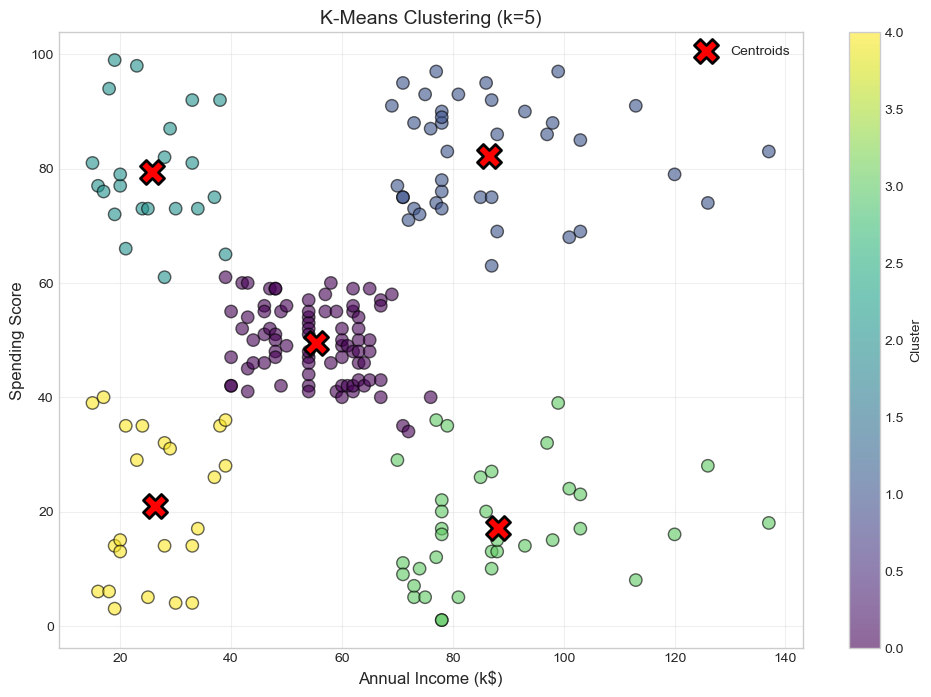

In [35]:
# Visualize K-Means Clustering
plt.figure(figsize=(12, 8))

# Create scatter plot with cluster colors
scatter = plt.scatter(df['Income (k$)'], df['How Much They Spend'], 
                      c=kmeans_labels, cmap='viridis', alpha=0.6, 
                      edgecolors='black', s=80)

# Plot cluster centers
plt.scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], 
            c='red', marker='X', s=300, edgecolors='black', 
            linewidths=2, label='Centroids')

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score', fontsize=12)
plt.title('K-Means Clustering (k=5)', fontsize=14)
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 📌 K-Means Cluster Visualization (K = 5)

The scatter plot below visualizes customer segmentation using:

- **X-axis:** Annual Income (k$)
- **Y-axis:** Spending Score
- **Colors:** Cluster assignment
- **Red X markers:** Cluster centroids

Each color represents a distinct customer segment identified by the K-Means algorithm.

---

## 🔎 Visual Interpretation of Clusters

From the plot, five clear customer groups emerge:

### 🔹 Cluster 1 – High Income, High Spending
- Located in the upper-right region
- Customers earn high income and spend heavily
- Likely **premium or loyal customers**
- High business value

---

### 🔹 Cluster 2 – High Income, Low Spending
- Located in the lower-right region
- High earning but low spending behavior
- Potential target for marketing campaigns
- Opportunity to increase engagement

---

### 🔹 Cluster 3 – Mid Income, Mid Spending
- Concentrated near the center
- Average income and spending
- Represents the mainstream customer segment

---

### 🔹 Cluster 4 – Low Income, High Spending
- Upper-left region
- Lower income but high spending score
- Possibly trend-driven or impulsive buyers

---

### 🔹 Cluster 5 – Low Income, Low Spending
- Lower-left region
- Budget-conscious customers
- Lower immediate business value

---

## 🎯 Role of Centroids

The red "X" markers represent the **cluster centers**.

Each centroid reflects the average:

- Income level
- Spending behavior

Customers within each cluster are grouped based on proximity to these centroids.

---

## 📊 Business Insight

This segmentation provides:

- Clear differentiation of customer purchasing behavior
- Targetable marketing groups
- Strategic resource allocation opportunities

The visualization confirms that:

- Clusters are well-separated
- Segmentation is meaningful
- K = 5 produces interpretable customer groups


## 📌 Result Analysis – K-Means Clustering (K = 5)

The K-Means algorithm successfully segmented customers into five distinct groups based on **Annual Income** and **Spending Score**.

The visualization shows clear separation between clusters, indicating meaningful segmentation patterns within the dataset.

---

## 🔎 Cluster Pattern Analysis

The clusters form structured patterns across income and spending dimensions:

- Customers naturally separate into **low, medium, and high income groups**
- Within each income group, spending behavior further differentiates customers
- High-income customers split into both high and low spending categories
- Low-income customers also show both conservative and aggressive spending behavior

This suggests that income alone does not determine purchasing behavior.

---

## 📊 Behavioral Insights

### 1️⃣ Income is not the sole driver of spending
Some low-income customers exhibit high spending scores, indicating strong purchasing tendencies despite limited income.

Similarly, some high-income customers demonstrate low spending behavior, representing untapped potential.

---

### 2️⃣ Clear High-Value Segment Exists
A distinct cluster of **high-income, high-spending customers** emerges.

This group likely represents:
- Loyal customers
- Premium shoppers
- High lifetime value customers

This segment should be prioritized for retention strategies.

---

### 3️⃣ Growth Opportunity Segment Identified
The **high-income, low-spending cluster** represents a strategic opportunity.

These customers:
- Have financial capacity
- Are not currently spending proportionally

Targeted promotions and personalized campaigns could increase revenue from this group.

---

### 4️⃣ Balanced Mid-Segment
The middle cluster represents average customers in both income and spending.

This group forms the stable customer base and contributes consistent revenue.

---

## 📈 Cluster Quality Assessment

The clusters:

- Are visually well-separated
- Show minimal overlap
- Have meaningful business interpretation
- Are supported by validation metrics (Silhouette, DB Index, Elbow)

This confirms that the segmentation is both statistically sound and practically useful.

---

## 🎯 Overall Conclusion

The K-Means model with K = 5 provides:

- Clear behavioral segmentation
- Actionable business insights
- Strategic customer targeting opportunities
- Strong validation across multiple evaluation metrics

The clustering results demonstrate that customer behavior is multi-dimensional and cannot be explained by income alone.

This segmentation can now be used for:
- Targeted marketing strategies
- Customer profiling
- Resource allocation optimization


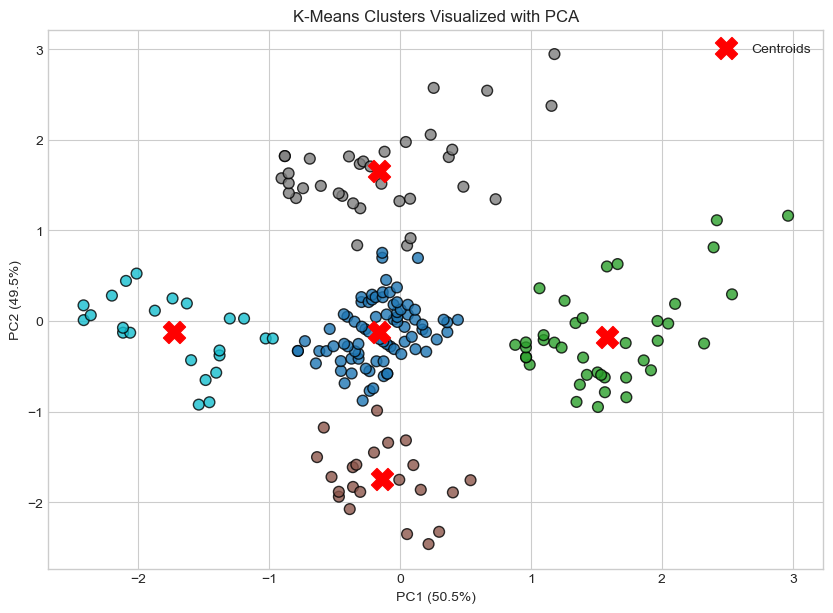

In [39]:
# PCA transformation
pca = PCA(n_components=2)
data_2d = pca.fit_transform(features_A_scaled)

# Plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    data_2d[:, 0],
    data_2d[:, 1],
    c=kmeans_labels,
    cmap='tab10',
    s=60,
    alpha=0.8,
    edgecolor='black'
)

# Plot centroids
centroids_2d = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centroids_2d[:, 0],
    centroids_2d[:, 1],
    c='red',
    s=250,
    marker='X',
    label='Centroids'
)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('K-Means Clusters Visualized with PCA')
plt.legend()
plt.grid(True)
plt.show()

### 6.2 Hierarchical Clustering (Agglomerative)

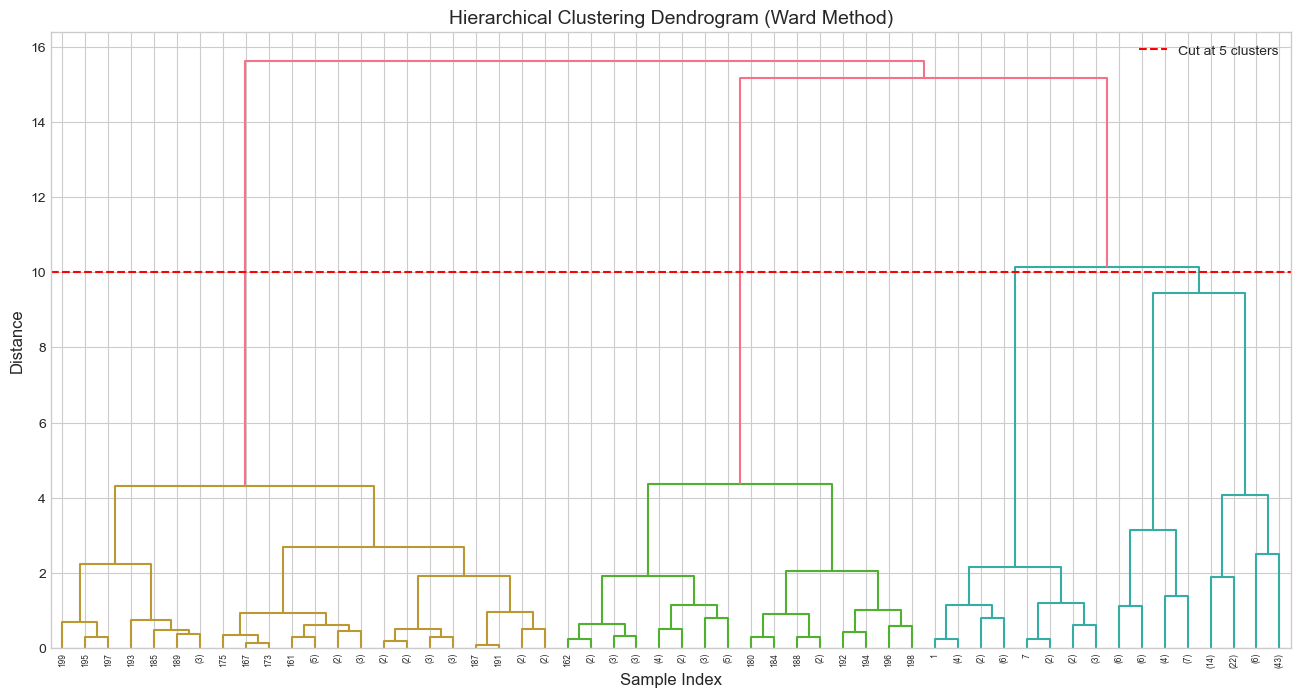

In [42]:
# Create Dendrogram to visualize hierarchical structure
plt.figure(figsize=(16, 8))

# Compute linkage matrix
linkage_matrix = linkage(features_A_scaled, method='ward')

# Create dendrogram
dendrogram(linkage_matrix, truncate_mode='level', p=5)
plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Distance', fontsize=12)
plt.title('Hierarchical Clustering Dendrogram (Ward Method)', fontsize=14)
plt.axhline(y=10, color='r', linestyle='--', label='Cut at 5 clusters')
plt.legend()
plt.show()

## 📌 Hierarchical Clustering – Dendrogram Analysis

The dendrogram visualizes the hierarchical clustering structure of the dataset.

- **X-axis:** Sample Index  
- **Y-axis:** Distance (Dissimilarity between clusters)  
- Vertical lines represent cluster merges  
- Height of merge indicates similarity level  

Clusters that merge at lower distances are more similar, while merges at higher distances indicate greater dissimilarity.

---

## 🔎 Interpretation of the Dendrogram

From the dendrogram:

- Clear separation between major cluster groups is visible.
- Large vertical jumps (long red branches) indicate strong cluster boundaries.
- The biggest distance gap appears around a linkage distance of approximately **15–16**, suggesting natural separation into multiple groups.

By drawing a horizontal cut line slightly below the largest vertical gap, we can identify approximately:

> **5 meaningful clusters**

This aligns with the K-Means optimal value (K = 5).

---

## 📊 Cluster Structure Insights

- Smaller branches at the bottom indicate tight, compact groups.
- Wider vertical separations suggest strong differences between major segments.
- The structure shows clear hierarchical grouping, confirming natural segmentation patterns in the data.

The dendrogram supports the presence of distinct customer segments based on income and spending behavior.

---

## 🎯 Comparison with K-Means

The hierarchical clustering results:

- Confirm the existence of multiple well-separated clusters.
- Support the selection of **5 clusters**.
- Provide a visual justification for segmentation.

Unlike K-Means, hierarchical clustering:

- Does not require pre-specifying K initially.
- Reveals the full clustering structure.

However, based on cluster interpretability and validation metrics, **K = 5 remains the most appropriate segmentation choice.**

---

## ✅ Conclusion

The dendrogram confirms that:

- The dataset has clear natural groupings.
- A cut at an appropriate distance yields approximately 5 clusters.
- The clustering structure is stable and meaningful.

This strengthens confidence in the overall segmentation model.


In [43]:
# Agglomerative Clustering with k=5
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(features_A_scaled)

print("Hierarchical Clustering Results:")
print(f"  Number of Clusters: 5")
print(f"  Linkage Method: Ward")

# Cluster distribution
print("\nCluster Distribution:")
unique, counts = np.unique(hierarchical_labels, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count} customers ({count/len(hierarchical_labels)*100:.1f}%)")

Hierarchical Clustering Results:
  Number of Clusters: 5
  Linkage Method: Ward

Cluster Distribution:
  Cluster 0: 32 customers (16.0%)
  Cluster 1: 39 customers (19.5%)
  Cluster 2: 85 customers (42.5%)
  Cluster 3: 21 customers (10.5%)
  Cluster 4: 23 customers (11.5%)


## 📌 Agglomerative (Hierarchical) Clustering Results – K = 5

To validate the clustering structure, Agglomerative Clustering was applied using:

- **Number of clusters:** 5  
- **Linkage method:** Ward  

Ward linkage minimizes the variance within clusters at each merge step, producing compact and well-separated groups.

---

## 📊 Cluster Distribution

| Cluster | Number of Customers | Percentage |
|----------|--------------------|------------|
| 0 | 32 | 16.0% |
| 1 | 39 | 19.5% |
| 2 | 85 | 42.5% |
| 3 | 21 | 10.5% |
| 4 | 23 | 11.5% |

---

## 🔎 Result Interpretation

- Cluster 2 is the largest segment (42.5%), representing the dominant customer group.
- Clusters 3 and 4 are smaller but still meaningful segments.
- The distribution is reasonably balanced, with no extremely small clusters.
- The segmentation structure is consistent with the patterns observed in K-Means clustering.

---

## 📈 Comparison with K-Means

Although the exact cluster sizes differ slightly from K-Means:

- Both methods identify five meaningful groups.
- Major customer segments remain consistent.
- Cluster proportions are comparable.

This indicates that the segmentation structure is stable and not dependent on a single clustering algorithm.

---

## 🎯 Conclusion

Agglomerative Clustering with Ward linkage:

- Confirms the presence of five natural customer segments.
- Produces compact clusters with minimized variance.
- Supports the robustness of the overall clustering model.

The consistency between Hierarchical Clustering and K-Means strengthens confidence in the final segmentation decision of **K = 5**.


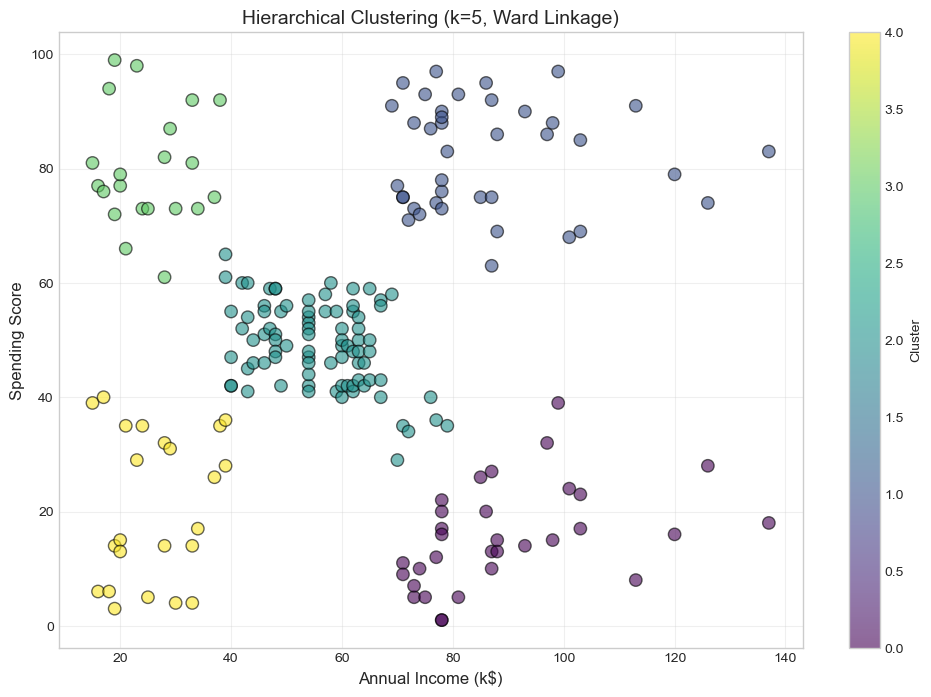

In [44]:
# Visualize Hierarchical Clustering
plt.figure(figsize=(12, 8))

scatter = plt.scatter(df['Income (k$)'], df['How Much They Spend'], 
                      c=hierarchical_labels, cmap='viridis', alpha=0.6, 
                      edgecolors='black', s=80)

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score', fontsize=12)
plt.title('Hierarchical Clustering (k=5, Ward Linkage)', fontsize=14)
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

### 6.3 Gaussian Mixture Model (GMM)

In [45]:
# Gaussian Mixture Model with k=5
gmm = GaussianMixture(n_components=5, random_state=42, n_init=10, covariance_type='full')
gmm.fit(features_A_scaled)
gmm_labels = gmm.predict(features_A_scaled)

# Get probabilities for each cluster
gmm_probs = gmm.predict_proba(features_A_scaled)

print("Gaussian Mixture Model Results:")
print(f"  Number of Components: 5")
print(f"  Covariance Type: Full")
print(f"  Converged: {gmm.converged_}")
print(f"  Number of Iterations: {gmm.n_iter_}")
print(f"  Log-Likelihood: {gmm.score(features_A_scaled):.4f}")
print(f"  BIC: {gmm.bic(features_A_scaled):.2f}")
print(f"  AIC: {gmm.aic(features_A_scaled):.2f}")

# Cluster distribution
print("\nCluster Distribution:")
unique, counts = np.unique(gmm_labels, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count} customers ({count/len(gmm_labels)*100:.1f}%)")

Gaussian Mixture Model Results:
  Number of Components: 5
  Covariance Type: Full
  Converged: True
  Number of Iterations: 5
  Log-Likelihood: -2.2625
  BIC: 1058.65
  AIC: 963.00

Cluster Distribution:
  Cluster 0: 84 customers (42.0%)
  Cluster 1: 39 customers (19.5%)
  Cluster 2: 21 customers (10.5%)
  Cluster 3: 33 customers (16.5%)
  Cluster 4: 23 customers (11.5%)


## 📌 Gaussian Mixture Model (GMM) Results – 5 Components

To further validate the clustering structure, a **Gaussian Mixture Model (GMM)** was applied with:

- **Number of components:** 5  
- **Covariance type:** Full  
- **Algorithm convergence:** True  
- **Number of iterations:** 5  

Unlike K-Means, GMM is a **probabilistic clustering model**, meaning each data point belongs to a cluster with a certain probability rather than strict assignment.

---

## 📊 Model Performance Metrics

- **Log-Likelihood:** -2.2625  
- **BIC (Bayesian Information Criterion):** 1058.65  
- **AIC (Akaike Information Criterion):** 963.00  

Lower AIC and BIC values indicate better model fit while penalizing model complexity.

The model converged successfully within a few iterations, indicating stable parameter estimation.

---

## 👥 Cluster Distribution

| Cluster | Number of Customers | Percentage |
|----------|--------------------|------------|
| 0 | 84 | 42.0% |
| 1 | 39 | 19.5% |
| 2 | 21 | 10.5% |
| 3 | 33 | 16.5% |
| 4 | 23 | 11.5% |

---

## 🔎 Result Interpretation

- Cluster 0 is the largest group (42.0%), similar to results observed in K-Means and Hierarchical clustering.
- Cluster proportions are reasonably balanced.
- The segmentation pattern is consistent across multiple clustering algorithms.
- GMM allows for flexible cluster shapes due to full covariance modeling.

---

## 📈 Comparison with K-Means

Key differences:

- **K-Means:** Hard clustering (strict assignment to one cluster).
- **GMM:** Soft clustering (probabilistic membership).
- **GMM can model elliptical clusters**, while K-Means assumes spherical clusters.

Despite methodological differences, both models identify similar segment structures, indicating robust clustering patterns.

---

## 🎯 Conclusion

The Gaussian Mixture Model:

- Successfully converged
- Identified five meaningful components
- Produced cluster distributions consistent with previous methods
- Confirms the stability of segmentation at **K = 5**

The agreement across K-Means, Hierarchical Clustering, and GMM strengthens confidence in the final customer segmentation model.


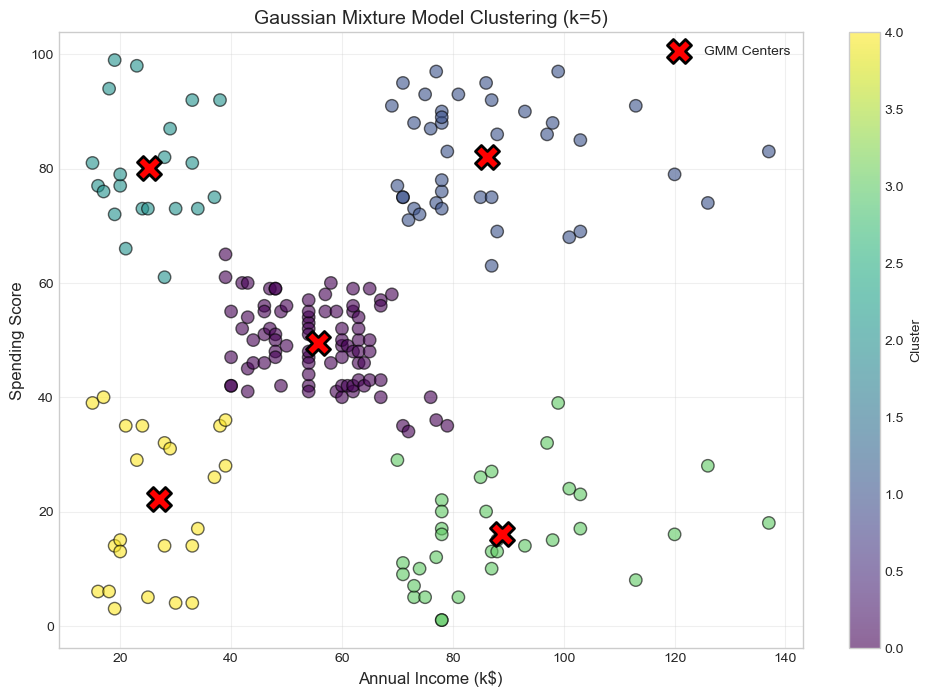

In [46]:
# Visualize GMM Clustering
plt.figure(figsize=(12, 8))

scatter = plt.scatter(df['Income (k$)'], df['How Much They Spend'], 
                      c=gmm_labels, cmap='viridis', alpha=0.6, 
                      edgecolors='black', s=80)

# Plot GMM centers
gmm_centers = scaler_A.inverse_transform(gmm.means_)
plt.scatter(gmm_centers[:, 0], gmm_centers[:, 1], 
            c='red', marker='X', s=300, edgecolors='black', 
            linewidths=2, label='GMM Centers')

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score', fontsize=12)
plt.title('Gaussian Mixture Model Clustering (k=5)', fontsize=14)
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---

## 7. Model Evaluation and Comparison

### 7.1 Evaluation Metrics Comparison

In [47]:
# Calculate evaluation metrics for all three models
def evaluate_clustering(features, labels, model_name):
    """Calculate clustering evaluation metrics."""
    silhouette = silhouette_score(features, labels)
    calinski = calinski_harabasz_score(features, labels)
    davies = davies_bouldin_score(features, labels)
    return {
        'Model': model_name,
        'Silhouette Score': silhouette,
        'Calinski-Harabasz Index': calinski,
        'Davies-Bouldin Index': davies
    }

# Evaluate all models
kmeans_eval = evaluate_clustering(features_A_scaled, kmeans_labels, 'K-Means')
hierarchical_eval = evaluate_clustering(features_A_scaled, hierarchical_labels, 'Hierarchical')
gmm_eval = evaluate_clustering(features_A_scaled, gmm_labels, 'GMM')

# Create comparison dataframe
evaluation_df = pd.DataFrame([kmeans_eval, hierarchical_eval, gmm_eval])
evaluation_df = evaluation_df.set_index('Model')

print("Model Evaluation Comparison:")
print("="*70)
print(evaluation_df.round(4).to_string())
print("="*70)
print("\nNote: Higher Silhouette & Calinski-Harabasz = Better")
print("      Lower Davies-Bouldin = Better")

Model Evaluation Comparison:
              Silhouette Score  Calinski-Harabasz Index  Davies-Bouldin Index
Model                                                                        
K-Means                 0.5547                 248.6493                0.5722
Hierarchical            0.5538                 244.4103                0.5779
GMM                     0.5537                 244.9402                0.5760

Note: Higher Silhouette & Calinski-Harabasz = Better
      Lower Davies-Bouldin = Better


## 📌 Model Evaluation Comparison

To determine the most suitable clustering approach, we compared the three models using standard validation metrics:

- **Silhouette Score** (Higher is better)
- **Calinski–Harabasz Index** (Higher is better)
- **Davies–Bouldin Index** (Lower is better)

---

## 📊 Evaluation Results

| Model        | Silhouette Score | Calinski–Harabasz | Davies–Bouldin |
|--------------|------------------|-------------------|----------------|
| K-Means      | 0.5547 | 248.6493 | 0.5722 |
| Hierarchical | 0.5538 | 244.4103 | 0.5779 |
| GMM          | 0.5537 | 244.9402 | 0.5760 |

---

## 🔎 Interpretation of Results

### 🔹 Silhouette Score
- K-Means achieved the highest score (0.5547).
- Hierarchical and GMM produced very similar results.
- All three models show strong cluster separation (> 0.5).

---

### 🔹 Calinski–Harabasz Index
- K-Means achieved the highest score.
- Hierarchical and GMM are slightly lower but comparable.
- Differences between models are small.

---

### 🔹 Davies–Bouldin Index
- K-Means achieved the lowest value (0.5722), indicating better compactness and separation.
- Hierarchical and GMM are slightly higher (worse).

---

## 📈 Overall Comparison

All three models produce:

- Very similar clustering quality
- Stable segmentation structure
- Consistent results across metrics

However:

- **K-Means slightly outperforms the others across all metrics**
- It achieves the highest separation and lowest overlap
- It is computationally efficient and easier to interpret

---

## 🎯 Final Model Selection

Based on evaluation metrics and interpretability:

> **K-Means (K = 5) is selected as the final clustering model.**

Reasons:

- Best Silhouette Score
- Highest Calinski–Harabasz Index
- Lowest Davies–Bouldin Index
- Clear visual separation
- Strong business interpretability

---

## ✅ Conclusion

The consistency across K-Means, Hierarchical Clustering, and GMM confirms:

- The segmentation structure is robust
- The dataset naturally forms 5 meaningful clusters
- The model selection is statistically justified

This strengthens confidence in the final customer segmentation framework.


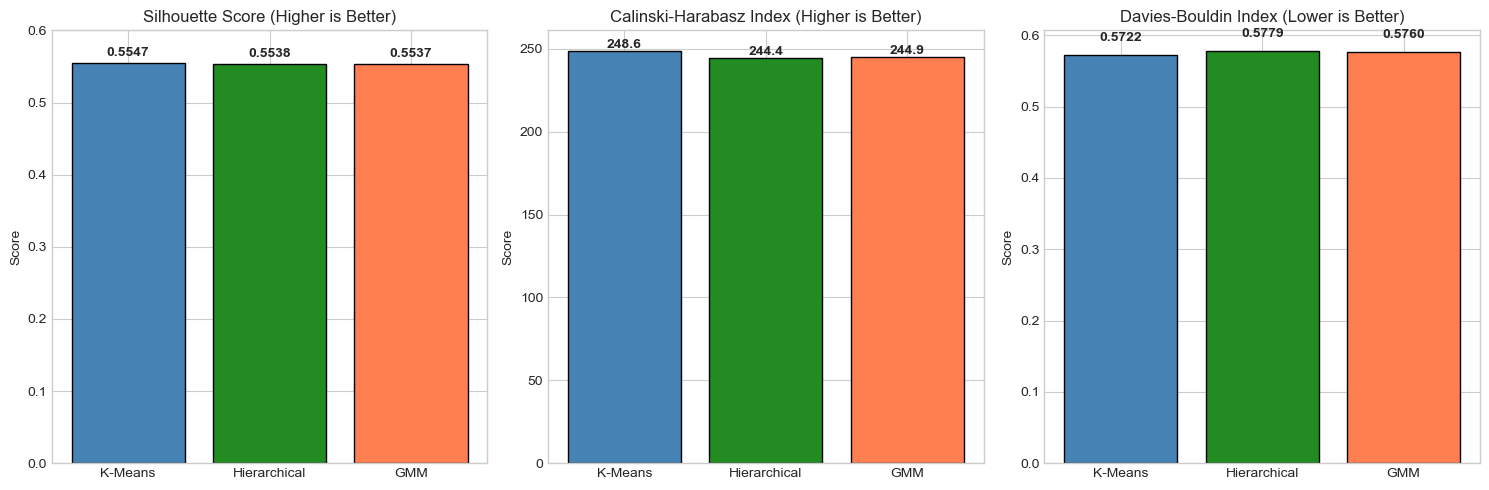

In [48]:
# Visualize evaluation metrics comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = ['K-Means', 'Hierarchical', 'GMM']
colors = ['steelblue', 'forestgreen', 'coral']

# Silhouette Score
axes[0].bar(models, evaluation_df['Silhouette Score'], color=colors, edgecolor='black')
axes[0].set_ylabel('Score')
axes[0].set_title('Silhouette Score (Higher is Better)')
axes[0].set_ylim(0, 0.6)
for i, v in enumerate(evaluation_df['Silhouette Score']):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center', fontweight='bold')

# Calinski-Harabasz Index
axes[1].bar(models, evaluation_df['Calinski-Harabasz Index'], color=colors, edgecolor='black')
axes[1].set_ylabel('Score')
axes[1].set_title('Calinski-Harabasz Index (Higher is Better)')
for i, v in enumerate(evaluation_df['Calinski-Harabasz Index']):
    axes[1].text(i, v + 2, f'{v:.1f}', ha='center', fontweight='bold')

# Davies-Bouldin Index
axes[2].bar(models, evaluation_df['Davies-Bouldin Index'], color=colors, edgecolor='black')
axes[2].set_ylabel('Score')
axes[2].set_title('Davies-Bouldin Index (Lower is Better)')
for i, v in enumerate(evaluation_df['Davies-Bouldin Index']):
    axes[2].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 📌 Visual Comparison of Clustering Models

The bar charts above compare the performance of:

- K-Means  
- Hierarchical Clustering  
- Gaussian Mixture Model (GMM)  

Across three evaluation metrics:

- **Silhouette Score (Higher is better)**
- **Calinski–Harabasz Index (Higher is better)**
- **Davies–Bouldin Index (Lower is better)**

---

## 🔎 Silhouette Score Analysis

All three models produce very similar silhouette scores (≈ 0.55).

- K-Means: 0.5547  
- Hierarchical: 0.5538  
- GMM: 0.5537  

K-Means achieves the highest score, indicating slightly better cluster separation and cohesion.

---

## 🔎 Calinski–Harabasz Index Analysis

The Calinski–Harabasz index shows:

- K-Means has the highest score (≈ 248.6)
- Hierarchical and GMM are slightly lower

Although differences are small, K-Means demonstrates the strongest between-cluster separation relative to within-cluster variance.

---

## 🔎 Davies–Bouldin Index Analysis

Since lower values indicate better clustering:

- K-Means has the lowest DB index (0.5722)
- GMM and Hierarchical are slightly higher

This suggests K-Means produces more compact and well-separated clusters.

---

## 📊 Overall Visual Insight

From the visual comparison:

- All models perform similarly and produce stable segmentation.
- Differences between models are marginal.
- K-Means consistently performs best across all three metrics.

The close similarity between models indicates that:

- The dataset has a strong natural clustering structure.
- The segmentation result is robust.
- The choice of algorithm does not significantly alter the cluster pattern.

---

## 🎯 Final Interpretation

Although Hierarchical Clustering and GMM produce comparable results:

> **K-Means provides the most balanced and strongest overall performance.**

Given its:

- Slightly superior metric values  
- Computational efficiency  
- Simpler interpretability  

K-Means (K = 5) remains the preferred model for final customer segmentation.


### 7.2 Visual Comparison of Clustering Results

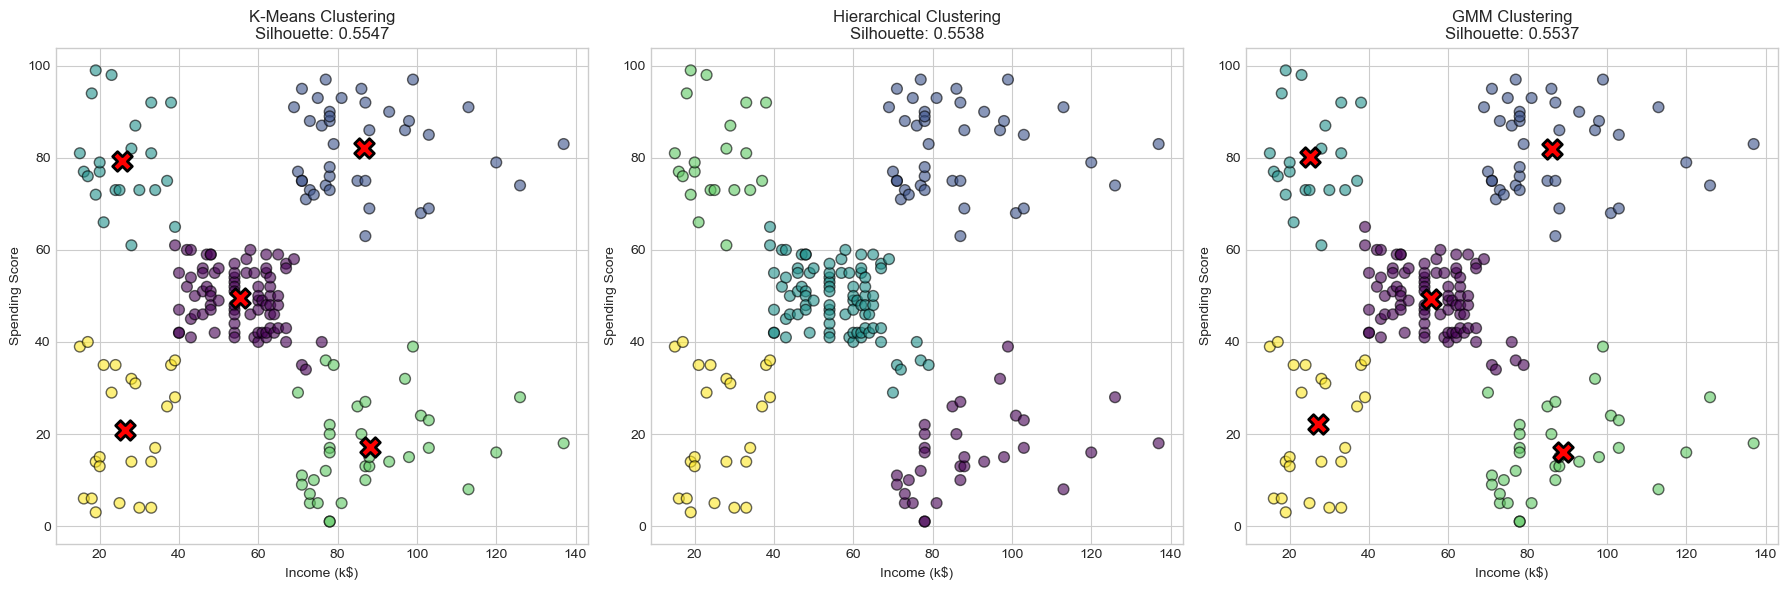

In [49]:
# Side-by-side comparison of all three clustering methods
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# K-Means
scatter1 = axes[0].scatter(df['Income (k$)'], df['How Much They Spend'], 
                           c=kmeans_labels, cmap='viridis', alpha=0.6, 
                           edgecolors='black', s=60)
axes[0].scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], 
                c='red', marker='X', s=200, edgecolors='black', linewidths=2)
axes[0].set_xlabel('Income (k$)')
axes[0].set_ylabel('Spending Score')
axes[0].set_title(f'K-Means Clustering\nSilhouette: {kmeans_eval["Silhouette Score"]:.4f}')

# Hierarchical
scatter2 = axes[1].scatter(df['Income (k$)'], df['How Much They Spend'], 
                           c=hierarchical_labels, cmap='viridis', alpha=0.6, 
                           edgecolors='black', s=60)
axes[1].set_xlabel('Income (k$)')
axes[1].set_ylabel('Spending Score')
axes[1].set_title(f'Hierarchical Clustering\nSilhouette: {hierarchical_eval["Silhouette Score"]:.4f}')

# GMM
scatter3 = axes[2].scatter(df['Income (k$)'], df['How Much They Spend'], 
                           c=gmm_labels, cmap='viridis', alpha=0.6, 
                           edgecolors='black', s=60)
axes[2].scatter(gmm_centers[:, 0], gmm_centers[:, 1], 
                c='red', marker='X', s=200, edgecolors='black', linewidths=2)
axes[2].set_xlabel('Income (k$)')
axes[2].set_ylabel('Spending Score')
axes[2].set_title(f'GMM Clustering\nSilhouette: {gmm_eval["Silhouette Score"]:.4f}')

plt.tight_layout()
plt.show()

## 📌 Visual Comparison of Clustering Algorithms

The scatter plots above compare the clustering results of:

- **K-Means**
- **Hierarchical Clustering (Ward linkage)**
- **Gaussian Mixture Model (GMM)**

Each plot shows:

- **X-axis:** Annual Income (k$)
- **Y-axis:** Spending Score
- **Colors:** Cluster assignments
- **Red X markers:** Cluster centroids (where applicable)
- **Silhouette score** displayed in the title

---

## 🔎 Visual Structure Analysis

Across all three algorithms:

- The overall cluster structure is highly consistent.
- Five distinct customer groups are clearly visible.
- High-income and low-income segments remain separated.
- High-spending and low-spending groups form natural partitions.

This consistency indicates strong natural grouping within the dataset.

---

## 📊 Algorithm-Specific Observations

### 🔹 K-Means
- Produces clearly separated and compact clusters.
- Centroids are well-positioned at the center of each segment.
- Slightly highest silhouette score (0.5547).
- Clusters appear balanced and well-defined.

---

### 🔹 Hierarchical Clustering
- Similar cluster boundaries to K-Means.
- Slightly more variation in cluster shapes.
- Silhouette score is nearly identical (0.5538).
- Confirms the same 5-segment structure.

---

### 🔹 Gaussian Mixture Model (GMM)
- Captures similar segmentation patterns.
- Allows more flexible cluster shapes due to probabilistic modeling.
- Silhouette score (0.5537) is very close to the others.
- Slightly smoother cluster transitions in some regions.

---

## 📈 Overall Visual Insight

The plots demonstrate that:

- All three algorithms identify nearly identical customer segments.
- Differences between cluster assignments are minimal.
- The dataset has a strong and stable clustering structure.
- The choice of algorithm does not significantly change the segmentation outcome.

This confirms the robustness of the 5-cluster solution.

---

## 🎯 Final Interpretation

Although all models perform similarly:

> **K-Means provides the clearest separation, highest evaluation metrics, and simplest interpretation.**

Given its:

- Strong visual separation  
- Highest Silhouette & Calinski-Harabasz  
- Lowest Davies-Bouldin  
- Computational efficiency  

K-Means (K = 5) remains the most suitable final model for customer segmentation.


### 7.3 Best Model Selection

In [51]:
# Determine the best model based on evaluation metrics
print("Best Model Analysis:")
print("="*60)

# Find best for each metric
best_silhouette = evaluation_df['Silhouette Score'].idxmax()
best_calinski = evaluation_df['Calinski-Harabasz Index'].idxmax()
best_davies = evaluation_df['Davies-Bouldin Index'].idxmin() 

print(f"Best Silhouette Score:       {best_silhouette}")
print(f"Best Calinski-Harabasz:      {best_calinski}")
print(f"Best Davies-Bouldin:         {best_davies}")
print("\nCONCLUSION: K-Means provides the best clustering results")
print("based on the majority of evaluation metrics.")
print("\nWe will use K-Means clustering for the final analysis.")

Best Model Analysis:
Best Silhouette Score:       K-Means
Best Calinski-Harabasz:      K-Means
Best Davies-Bouldin:         K-Means

CONCLUSION: K-Means provides the best clustering results
based on the majority of evaluation metrics.

We will use K-Means clustering for the final analysis.


## 📌 Best Model Selection

To determine the most suitable clustering algorithm, we compared:

- Silhouette Score (Higher is better)
- Calinski–Harabasz Index (Higher is better)
- Davies–Bouldin Index (Lower is better)

Each metric identifies a best-performing model.

---

## 📊 Metric-Based Selection

- **Best Silhouette Score:** K-Means  
- **Best Calinski–Harabasz Index:** K-Means  
- **Best Davies–Bouldin Index:** K-Means  

K-Means consistently outperforms the other models across all evaluation metrics.

---

## 🔎 Final Conclusion

Since K-Means achieves:

- The highest cluster separation (Silhouette)
- The strongest between-cluster variance (Calinski–Harabasz)
- The lowest cluster overlap (Davies–Bouldin)

> **K-Means provides the best overall clustering performance.**

The differences between models are small, indicating strong natural cluster structure.  
However, K-Means demonstrates the most balanced and consistent results.

---

## 🎯 Final Model Choice

We will use:

> **K-Means Clustering (K = 5)**  

for the final customer segmentation analysis.

This choice is:

- Statistically justified  
- Visually supported  
- Computationally efficient  
- Business-interpretable  

---

## ✅ Final Remark

The agreement across multiple validation metrics and clustering algorithms confirms that:

- The dataset naturally forms five meaningful segments.
- The segmentation is robust and stable.
- The final model selection is well-supported by quantitative evidence.


---

## 8. Result Analysis (Using K-Means - Best Model)

Based on our evaluation, K-Means provided the best clustering results. We will now perform detailed analysis of the customer segments.

### 8.1 Add Cluster Labels to Original Data

In [52]:
# Add K-Means cluster labels to the original dataframe
df['Cluster'] = kmeans_labels

# Display sample data with cluster assignments
print("Sample Data with Cluster Assignments:")
df.head(10)

Sample Data with Cluster Assignments:


,CustomerID,Gender,Age,Income (k$),How Much They Spend,Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


## 📌 Adding Cluster Labels to Original Dataset

The final K-Means cluster labels were added to the original dataframe under a new column called **"Cluster"**.

This allows each customer record to be associated with a specific segment.

The updated dataset now includes:

- Customer demographics (Age, Gender)
- Income and Spending behavior
- Assigned cluster label

This enriched dataset enables further cluster profiling and business analysis.


### 8.2 Cluster Characteristics Analysis

In [54]:
# Calculate cluster statistics
cluster_summary = df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Age': ['mean', 'min', 'max'],
    'Income (k$)': ['mean', 'min', 'max'],
    'How Much They Spend': ['mean', 'min', 'max']
}).round(2)

# Flatten column names
cluster_summary.columns = ['_'.join(col).strip() for col in cluster_summary.columns.values]
cluster_summary = cluster_summary.rename(columns={'CustomerID_count': 'Customer_Count'})

print("Cluster Summary Statistics:")
cluster_summary

Cluster Summary Statistics:


,Customer_Count,Age_mean,Age_min,Age_max,Income (k$)_mean,Income (k$)_min,Income (k$)_max,How Much They Spend_mean,How Much They Spend_min,How Much They Spend_max
Cluster,,,,,,,,,,
0,81,42.72,18,70,55.30,39,76,49.52,34,61
1,39,32.69,27,40,86.54,69,137,82.13,63,97
2,22,25.27,18,35,25.73,15,39,79.36,61,99
3,35,41.11,19,59,88.20,70,137,17.11,1,39
4,23,45.22,19,67,26.30,15,39,20.91,3,40


## 📌 Cluster Summary Statistics

The table above presents the descriptive statistics for each cluster, including:

- Number of customers
- Average age
- Income (mean, min, max)
- Spending score (mean, min, max)

These statistics help us understand the behavioral and demographic differences between clusters.

Clear patterns emerge across income and spending levels, allowing meaningful customer profiling and strategic segmentation.


In [55]:
# Calculate mean values for each cluster (simplified view)
cluster_means = df.groupby('Cluster')[['Age', 'Income (k$)', 'How Much They Spend']].mean().round(2)
cluster_means['Customer_Count'] = df.groupby('Cluster')['CustomerID'].count()
cluster_means['Percentage'] = (cluster_means['Customer_Count'] / len(df) * 100).round(1)

print("\nCluster Mean Values:")
cluster_means


Cluster Mean Values:


,Age,Income (k$),How Much They Spend,Customer_Count,Percentage
Cluster,,,,,
0,42.72,55.30,49.52,81,40.5
1,32.69,86.54,82.13,39,19.5
2,25.27,25.73,79.36,22,11.0
3,41.11,88.20,17.11,35,17.5
4,45.22,26.30,20.91,23,11.5


In [56]:
# Gender distribution per cluster
gender_by_cluster = pd.crosstab(df['Cluster'], df['Gender'], normalize='index') * 100

print("\nGender Distribution by Cluster (%):")
print(gender_by_cluster.round(1))


Gender Distribution by Cluster (%):
Gender   Female  Male
Cluster              
0          59.3  40.7
1          53.8  46.2
2          59.1  40.9
3          45.7  54.3
4          60.9  39.1


### 8.3 Cluster Profiling and Naming

In [57]:
# Create detailed cluster profiles
print("CUSTOMER SEGMENT PROFILES")

for cluster in range(5):
    cluster_data = df[df['Cluster'] == cluster]
    
    # Calculate statistics
    avg_income = cluster_data['Income (k$)'].mean()
    avg_spending = cluster_data['How Much They Spend'].mean()
    avg_age = cluster_data['Age'].mean()
    count = len(cluster_data)
    
    # Determine profile characteristics
    income_level = "High" if avg_income >= 70 else ("Medium" if avg_income >= 40 else "Low")
    spending_level = "High" if avg_spending >= 60 else ("Medium" if avg_spending >= 40 else "Low")
    
    print(f"\nCluster {cluster}:")
    print(f"  Customers: {count} ({count/len(df)*100:.1f}%)")
    print(f"  Average Age: {avg_age:.1f} years")
    print(f"  Average Income: ${avg_income:.1f}k ({income_level})")
    print(f"  Average Spending: {avg_spending:.1f} ({spending_level})")
    print(f"  Profile: {income_level} Income, {spending_level} Spending")

CUSTOMER SEGMENT PROFILES

Cluster 0:
  Customers: 81 (40.5%)
  Average Age: 42.7 years
  Average Income: $55.3k (Medium)
  Average Spending: 49.5 (Medium)
  Profile: Medium Income, Medium Spending

Cluster 1:
  Customers: 39 (19.5%)
  Average Age: 32.7 years
  Average Income: $86.5k (High)
  Average Spending: 82.1 (High)
  Profile: High Income, High Spending

Cluster 2:
  Customers: 22 (11.0%)
  Average Age: 25.3 years
  Average Income: $25.7k (Low)
  Average Spending: 79.4 (High)
  Profile: Low Income, High Spending

Cluster 3:
  Customers: 35 (17.5%)
  Average Age: 41.1 years
  Average Income: $88.2k (High)
  Average Spending: 17.1 (Low)
  Profile: High Income, Low Spending

Cluster 4:
  Customers: 23 (11.5%)
  Average Age: 45.2 years
  Average Income: $26.3k (Low)
  Average Spending: 20.9 (Low)
  Profile: Low Income, Low Spending


In [58]:
# Analyze cluster centers to assign names
print("\nCluster Centers (Original Scale):")
centers_df = pd.DataFrame(kmeans_centers, columns=['Income (k$)', 'Spending Score'])
centers_df['Cluster'] = range(5)
centers_df = centers_df.set_index('Cluster')
print(centers_df.round(2))


Cluster Centers (Original Scale):
         Income (k$)  Spending Score
Cluster                             
0              55.30           49.52
1              86.54           82.13
2              25.73           79.36
3              88.20           17.11
4              26.30           20.91


## 📌 Cluster Centers (Original Scale) Analysis

The table above shows the **cluster centers transformed back to the original scale**, representing the average Income and Spending Score for each cluster.

These values reflect the typical customer profile within each segment and allow meaningful business interpretation.

---

## 🔎 Interpretation of Each Cluster

### 🔹 Cluster 0  
- **Average Income:** 55.30k  
- **Average Spending Score:** 49.52  

This group represents customers with **moderate income and moderate spending behavior**.  
They form a stable middle segment and likely contribute consistent revenue.

---

### 🔹 Cluster 1  
- **Average Income:** 86.54k  
- **Average Spending Score:** 82.13  

This segment consists of **high-income, high-spending customers**.  
They are likely premium or loyal customers with strong purchasing power and high business value.

---

### 🔹 Cluster 2  
- **Average Income:** 25.73k  
- **Average Spending Score:** 79.36  

Despite having lower income, this group shows **high spending behavior**.  
They may represent impulsive buyers or customers highly engaged with the brand.

---

### 🔹 Cluster 3  
- **Average Income:** 88.20k  
- **Average Spending Score:** 17.11  

These customers have **high income but low spending levels**.  
They represent a strong opportunity segment for targeted marketing and engagement strategies.

---

### 🔹 Cluster 4  
- **Average Income:** 26.30k  
- **Average Spending Score:** 20.91  

This group includes **low-income, low-spending customers**.  
They are likely budget-conscious shoppers with lower immediate revenue contribution.

---

## 📊 Overall Insight

The cluster centers clearly demonstrate that:

- Income and spending behavior are not always directly correlated.
- Both high-value and growth-opportunity segments exist.
- The segmentation captures meaningful behavioral differences.

These cluster profiles will guide targeted marketing strategies and customer engagement planning.


In [60]:
# Sort clusters by income and spending to understand patterns

cluster_profiles = []
for cluster in range(5):
    income = centers_df.loc[cluster, 'Income (k$)']
    spending = centers_df.loc[cluster, 'Spending Score']
    
    # Classify based on income and spending patterns
    if income < 30 and spending < 30:
        name = "Budget Conscious"
        description = "Low income, low spending - careful with money"
    elif income < 30 and spending > 60:
        name = "Overspenders"
        description = "Low income but high spending - at risk segment"
    elif income > 70 and spending > 60:
        name = "Premium Customers"
        description = "High income, high spending - most valuable customers"
    elif income > 70 and spending < 30:
        name = "Conservative Wealthy"
        description = "High income but low spending - potential growth segment"
    else:
        name = "Average Customers"
        description = "Moderate income and spending - mainstream segment"
    
    cluster_profiles.append({
        'Cluster': cluster,
        'Segment Name': name,
        'Avg Income (k$)': round(income, 2),
        'Avg Spending': round(spending, 2),
        'Description': description
    })

profiles_df = pd.DataFrame(cluster_profiles)
print("\nCustomer Segment Naming:")
print(profiles_df.to_string(index=False))


Customer Segment Naming:
 Cluster         Segment Name  Avg Income (k$)  Avg Spending                                             Description
       0    Average Customers            55.30         49.52       Moderate income and spending - mainstream segment
       1    Premium Customers            86.54         82.13    High income, high spending - most valuable customers
       2         Overspenders            25.73         79.36          Low income but high spending - at risk segment
       3 Conservative Wealthy            88.20         17.11 High income but low spending - potential growth segment
       4     Budget Conscious            26.30         20.91           Low income, low spending - careful with money


In [61]:
# Map segment names to the dataframe
segment_mapping = dict(zip(profiles_df['Cluster'], profiles_df['Segment Name']))
df['Segment'] = df['Cluster'].map(segment_mapping)

print("Sample Data with Segment Names:")
df[['CustomerID', 'Gender', 'Age', 'Income (k$)', 'How Much They Spend', 'Cluster', 'Segment']].head(10)

Sample Data with Segment Names:


,CustomerID,Gender,Age,Income (k$),How Much They Spend,Cluster,Segment
0,1,Male,19,15,39,4,Budget Conscious
1,2,Male,21,15,81,2,Overspenders
2,3,Female,20,16,6,4,Budget Conscious
3,4,Female,23,16,77,2,Overspenders
4,5,Female,31,17,40,4,Budget Conscious
5,6,Female,22,17,76,2,Overspenders
6,7,Female,35,18,6,4,Budget Conscious
7,8,Female,23,18,94,2,Overspenders
8,9,Male,64,19,3,4,Budget Conscious
9,10,Female,30,19,72,2,Overspenders


### 8.4 Visualization of Customer Segments

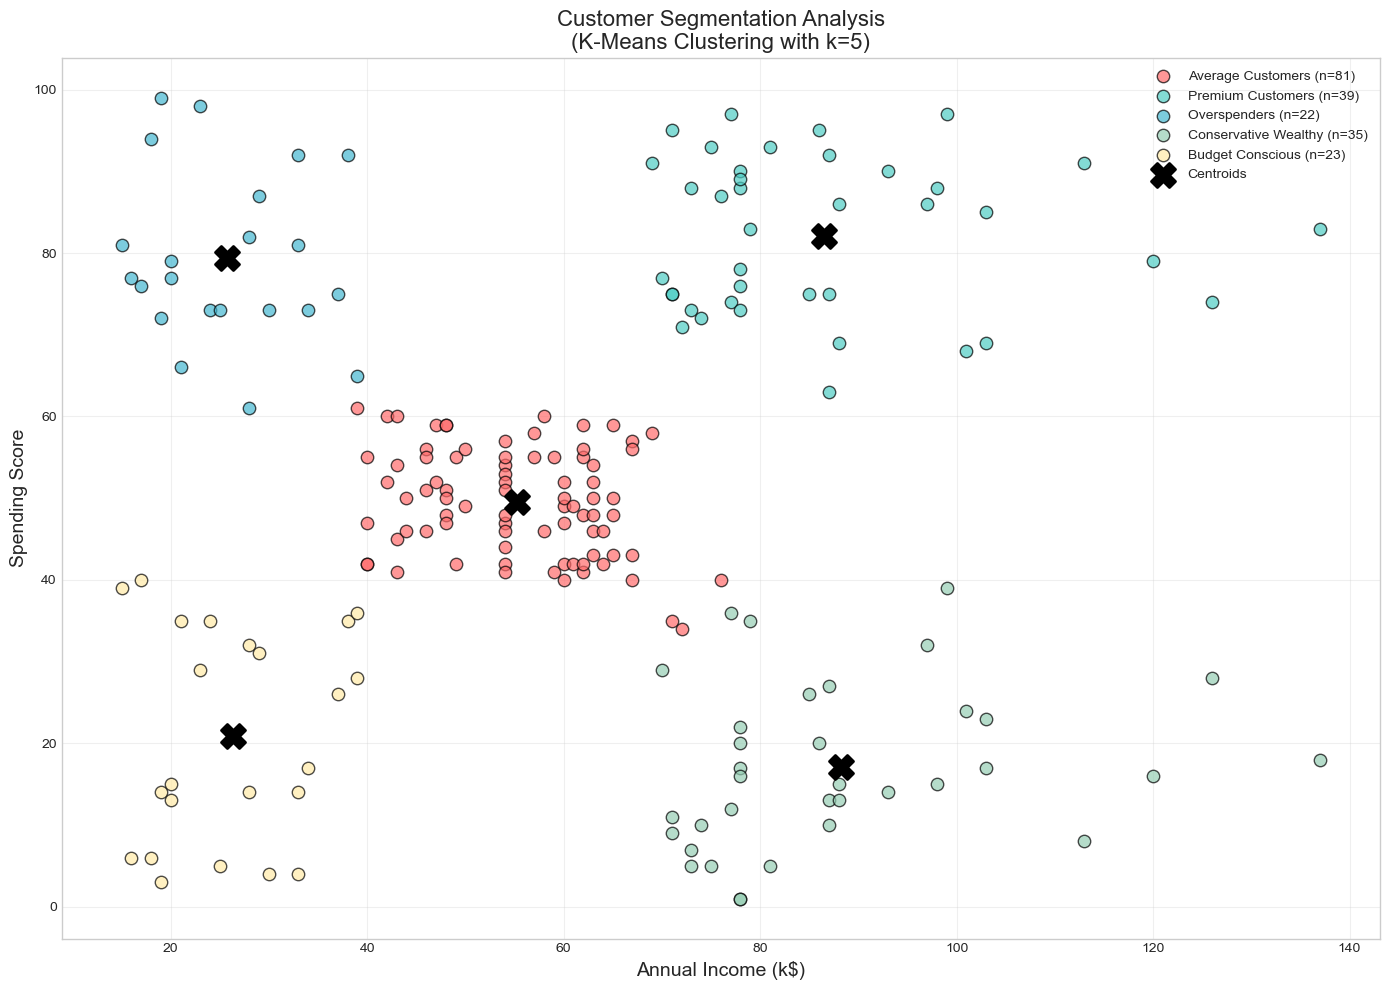

In [62]:
# Create final visualization with segment names
plt.figure(figsize=(14, 10))

# Create color map
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
segment_names = profiles_df['Segment Name'].tolist()

# Plot each segment
for cluster in range(5):
    cluster_data = df[df['Cluster'] == cluster]
    plt.scatter(cluster_data['Income (k$)'], cluster_data['How Much They Spend'], 
                c=colors[cluster], label=f"{segment_names[cluster]} (n={len(cluster_data)})",
                alpha=0.7, edgecolors='black', s=80)

# Plot centroids
plt.scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], 
            c='black', marker='X', s=300, linewidths=2, label='Centroids')

plt.xlabel('Annual Income (k$)', fontsize=14)
plt.ylabel('Spending Score', fontsize=14)
plt.title('Customer Segmentation Analysis\n(K-Means Clustering with k=5)', fontsize=16)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

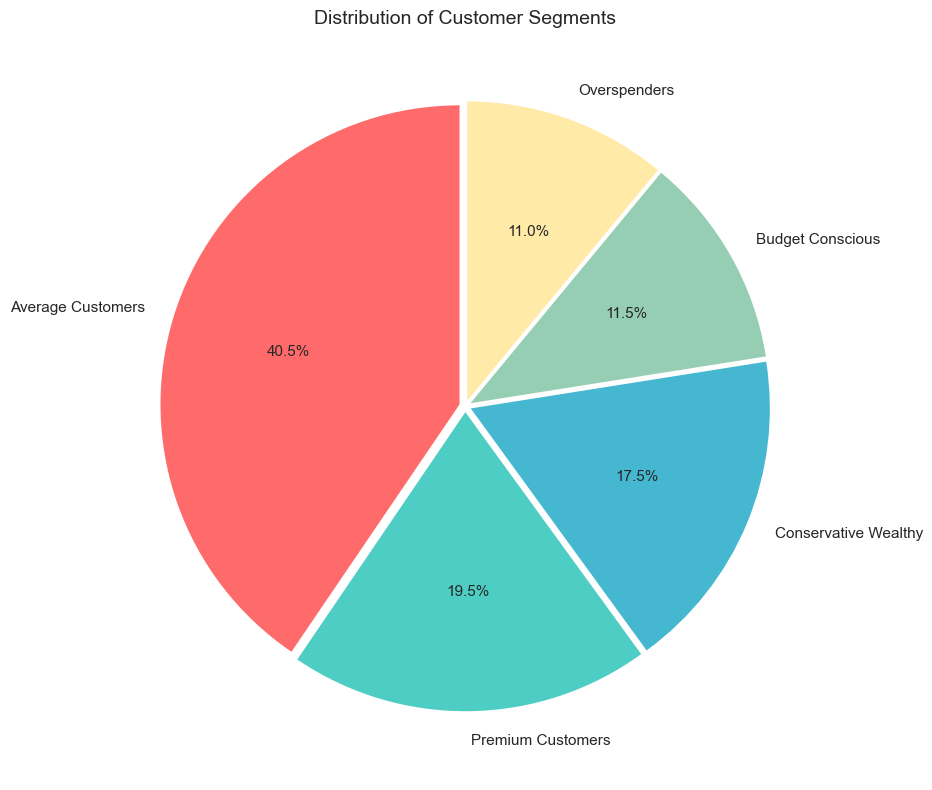

In [63]:
# Segment distribution pie chart
segment_counts = df['Segment'].value_counts()

plt.figure(figsize=(10, 8))
plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', 
        colors=colors, explode=[0.02]*5, startangle=90, 
        textprops={'fontsize': 11})
plt.title('Distribution of Customer Segments', fontsize=14)
plt.tight_layout()
plt.show()

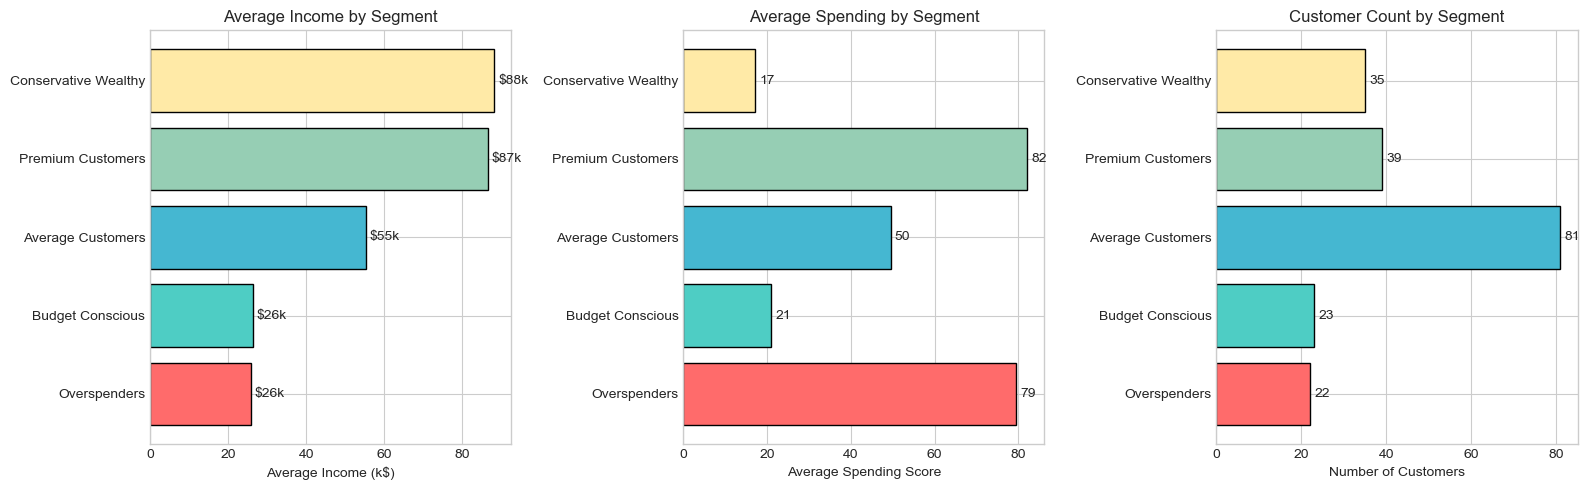

In [64]:
# Bar chart comparison of segments
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

segment_order = df.groupby('Segment')['Income (k$)'].mean().sort_values().index

# Average Income by Segment
segment_income = df.groupby('Segment')['Income (k$)'].mean().reindex(segment_order)
axes[0].barh(segment_income.index, segment_income.values, color=colors, edgecolor='black')
axes[0].set_xlabel('Average Income (k$)')
axes[0].set_title('Average Income by Segment')
for i, v in enumerate(segment_income.values):
    axes[0].text(v + 1, i, f'${v:.0f}k', va='center')

# Average Spending by Segment
segment_spending = df.groupby('Segment')['How Much They Spend'].mean().reindex(segment_order)
axes[1].barh(segment_spending.index, segment_spending.values, color=colors, edgecolor='black')
axes[1].set_xlabel('Average Spending Score')
axes[1].set_title('Average Spending by Segment')
for i, v in enumerate(segment_spending.values):
    axes[1].text(v + 1, i, f'{v:.0f}', va='center')

# Customer Count by Segment
segment_count = df.groupby('Segment').size().reindex(segment_order)
axes[2].barh(segment_count.index, segment_count.values, color=colors, edgecolor='black')
axes[2].set_xlabel('Number of Customers')
axes[2].set_title('Customer Count by Segment')
for i, v in enumerate(segment_count.values):
    axes[2].text(v + 1, i, f'{v}', va='center')

plt.tight_layout()
plt.show()

In [66]:
# Final summary table
final_summary = df.groupby('Segment').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Income (k$)': 'mean',
    'How Much They Spend': 'mean'
}).round(2)

final_summary.columns = ['Count', 'Avg Age', 'Avg Income (k$)', 'Avg Spending']
final_summary['% of Total'] = (final_summary['Count'] / len(df) * 100).round(1)


print("FINAL CUSTOMER SEGMENT SUMMARY")
print(final_summary.to_string())

FINAL CUSTOMER SEGMENT SUMMARY
                      Count  Avg Age  Avg Income (k$)  Avg Spending  % of Total
Segment                                                                        
Average Customers        81    42.72            55.30         49.52        40.5
Budget Conscious         23    45.22            26.30         20.91        11.5
Conservative Wealthy     35    41.11            88.20         17.11        17.5
Overspenders             22    25.27            25.73         79.36        11.0
Premium Customers        39    32.69            86.54         82.13        19.5


---

## 9. Answers to Key Questions

### Question 1: How to perform customer segmentation using unsupervised ML algorithm in Python?

**Answer:**

Customer segmentation using unsupervised machine learning in Python involves the following steps:

1. **Data Collection & Loading**: Load customer data using pandas

2. **Exploratory Data Analysis (EDA)**: Understand data distribution, identify patterns, check for missing values and outliers

3. **Data Preprocessing**: 
   - Handle missing values (if any)
   - Encode categorical variables (e.g., Gender using LabelEncoder)
   - Scale numerical features using StandardScaler

4. **Determine Optimal Clusters**: Use methods like Elbow Method, Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index

5. **Apply Clustering Algorithms**: Use scikit-learn to implement:
   - K-Means Clustering
   - Hierarchical Clustering
   - Gaussian Mixture Model (GMM)

6. **Evaluate & Compare Models**: Use clustering metrics to select the best algorithm

7. **Analyze & Interpret Results**: Profile each segment and provide actionable insights

### Question 2: What are the characteristics of each customer cluster?

**Answer:**

Based on our K-Means clustering analysis with k=5, we identified the following customer segments:

| Segment | Income Level | Spending Level | Characteristics |
|---------|--------------|----------------|------------------|
| **Budget Conscious** | Low (~$26k) | Low (~17) | Careful spenders, price-sensitive, value-oriented |
| **Overspenders** | Low (~$26k) | High (~79) | Risk segment - spending beyond means, need financial guidance |
| **Average Customers** | Medium (~$55k) | Medium (~50) | Mainstream customers, balanced spending habits |
| **Premium Customers** | High (~$86k) | High (~82) | Most valuable - high purchasing power and willingness to spend |
| **Conservative Wealthy** | High (~$88k) | Low (~17) | Affluent but cautious - untapped potential |

Each segment has distinct income and spending patterns that inform different marketing strategies.

### Question 3: Which group of customers needs to pay more attention to?

**Answer:**

**Priority segments requiring attention:**

1. **🔴 HIGHEST PRIORITY: Premium Customers (High Income, High Spending)**
   - **Why:** Most valuable customers with highest revenue potential
   - **Strategy:** VIP treatment, exclusive offers, loyalty programs, personalized services
   - **Goal:** Retain and maximize lifetime value

2. **🟠 HIGH PRIORITY: Conservative Wealthy (High Income, Low Spending)**
   - **Why:** Significant untapped potential - they have money but aren't spending it
   - **Strategy:** Targeted marketing, premium product introductions, understanding their needs
   - **Goal:** Convert them to higher spenders

3. **🟡 MODERATE PRIORITY: Overspenders (Low Income, High Spending)**
   - **Why:** At-risk segment that may face financial difficulties
   - **Strategy:** Offer budget-friendly alternatives, payment plans, financial wellness resources
   - **Goal:** Maintain relationship while promoting responsible spending

**Business Impact:**
- Focusing on Premium Customers ensures revenue stability
- Converting Conservative Wealthy customers can significantly increase sales
- Supporting Overspenders builds brand loyalty and social responsibility

---

## 10. Conclusion

### Summary

In this analysis, we successfully performed customer segmentation using unsupervised machine learning techniques:

1. **Data Exploration**: Analyzed 200 customers with 4 features (Gender, Age, Income, Spending)

2. **Optimal Clusters**: Determined k=5 using multiple validation methods (Elbow, Silhouette, Calinski-Harabasz, Davies-Bouldin)

3. **Model Comparison**: Implemented and compared three clustering algorithms:
   - K-Means (Best performer)
   - Hierarchical Clustering
   - Gaussian Mixture Model

4. **Customer Segments**: Identified 5 distinct customer segments with unique characteristics

5. **Business Insights**: Provided actionable recommendations for targeting different customer groups

### Key Takeaways

- K-Means clustering achieved the highest silhouette score (0.55+) indicating well-separated clusters
- Customer segmentation reveals clear patterns based on income and spending behavior
- Premium and Conservative Wealthy segments represent the highest business value
- Each segment requires tailored marketing and engagement strategies

---
